# **From Attention to Generation: An Ablation Study of Small Decoder-Only Transformers**
### **Project implementation**: Building a Mini-GPT from Scratch with PyTorch, KV Cache and Weight Quantization.
The Transformer architecture, introduced in the research paper Attention Is All You Need (Vaswani et al., 2017), revolutionized natural language processing by replacing recurrent architectures with attention-based mechanisms.

This project aims to understand how modern GPT-style language models work by implementing a small decoder-only Transformer entirely from scratch using PyTorch.

Rather than relying on pretrained language models or external APIs, we will build the architecture component by component, train it on real textual data, and investigate how architectural choices influence language modeling performance.

The project is organized around four main objectives:
1. Architecture implementation: Build a GPT-style language model with token embeddings, positional embeddings, masked multi-head self-attention, feed-forward networks and autoregressive generation.
2. Ablation study: Investigate the effects of model size, attention heads, context length, dropout and causal masking on model performance.
3. Inference optimization: Implement KV caching and investigate INT8 and INT4 weight quantization to measure their effects on generation speed, memory consumption and language-model quality.
4. Evaluation and deployment: Evaluate models using cross-entropy, perplexity, next-token accuracy, training time and generation throughput, then deploy the final model through a Streamlit interface.
The experiments will use a real language-modeling dataset, controlled configurations and reproducible evaluation procedures.

The ultimate objective is to understand not only how a Transformer generates text, but also why different architectural and optimization choices affect its performance.

Reference paper: Vaswani et al., Attention Is All You Need (2017). [Read the research paper](https://arxiv.org/abs/1706.03762)

### **Environment Setup and Reproducibility**
We will use Google Colab for GPU computation and Google Drive for permanent storage.

The main problem with Colab is that its runtime is temporary. When the session disconnects, variables, installed packages and files stored locally can disappear

In [2]:

# ============================================================
# STEP 0 — ENVIRONMENT SETUP AND REPRODUCIBILITY
# ============================================================

# 1. Install dependencies
%pip install -q datasets tokenizers matplotlib pandas tqdm psutil

# 2. Imports
import os
import json
import time
import random
import platform
import psutil
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from google.colab import drive

# 3. Mount Google Drive
drive.mount("/content/drive")

# 4. Create project structure
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Mini-GPT-Project"
)

DIRECTORIES = [
    "data/raw",
    "data/processed",
    "data/tokenizer",
    "checkpoints/bigram",
    "checkpoints/small_gpt",
    "checkpoints/medium_gpt",
    "checkpoints/best_model",
    "experiments/ablations",
    "experiments/kv_cache",
    "experiments/quantization",
    "results/metrics",
    "results/graphs",
    "results/generated_samples",
    "deployment/final_model",
    "reports"
]

for directory in DIRECTORIES:
    (PROJECT_DIR / directory).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project structure created.")

# 5. Inspect computational resources
print("\n" + "=" * 55)
print("HARDWARE INFORMATION")
print("=" * 55)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CPU cores:", os.cpu_count())

ram = psutil.virtual_memory()

print(f"Total RAM: {ram.total / 1024**3:.2f} GB")
print(f"Available RAM: {ram.available / 1024**3:.2f} GB")

gpu_info = {
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": "CPU",
    "gpu_memory_gb": 0
}

if torch.cuda.is_available():

    gpu = torch.cuda.get_device_properties(0)

    gpu_info["gpu_name"] = torch.cuda.get_device_name(0)

    gpu_info["gpu_memory_gb"] = round(
        gpu.total_memory / 1024**3, 2
    )

    print("GPU:", gpu_info["gpu_name"])
    print("GPU memory:", gpu_info["gpu_memory_gb"], "GB")
    print("CUDA:", torch.version.cuda)

else:
    print("GPU: Not available")

# 6. Configure reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("\nRandom seed configured:", SEED)

# 7. Initial project configuration
CONFIG = {
    "project_name": "Mini-GPT From Scratch",

    "research_title": (
        "From Attention to Generation: "
        "An Ablation Study of Small Decoder-Only Transformers"
    ),

    "seed": SEED,

    "dataset": "wikitext-103-raw-v1",

    "tokenizer": {
        "type": "BPE",
        "vocab_size": 8000
    },

    "model": {
        "context_length": 128,
        "embedding_dim": 128,
        "num_layers": 4,
        "num_heads": 4,
        "dropout": 0.1
    },

    "training": {
        "batch_size": 32,
        "learning_rate": 3e-4,
        "weight_decay": 0.01
    },

    "checkpoint": {
        "save_frequency": 500,
        "evaluation_frequency": 250
    },

    "device": (
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )
}

config_path = PROJECT_DIR / "config.json"

with open(config_path, "w") as f:
    json.dump(CONFIG, f, indent=4)

# 8. Save hardware information
hardware_info = {
    **gpu_info,
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cpu_cores": os.cpu_count(),
    "ram_total_gb": round(
        ram.total / 1024**3, 2
    )
}

with open(PROJECT_DIR / "hardware_info.json", "w") as f:
    json.dump(hardware_info, f, indent=4)

# 9. Checkpoint saving utility
def save_checkpoint(
    model,
    optimizer,
    step,
    config,
    history,
    filename="latest_checkpoint.pt"
):

    checkpoint_dir = PROJECT_DIR / "checkpoints"
    checkpoint_dir.mkdir(exist_ok=True)

    checkpoint_path = checkpoint_dir / filename
    temporary_path = checkpoint_dir / (filename + ".tmp")

    checkpoint = {
        "step": step,
        "model_state_dict": model.state_dict(),

        "optimizer_state_dict": (
            optimizer.state_dict()
            if optimizer is not None else None
        ),

        "config": config,
        "history": history,

        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),

        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else None
        )
    }

    torch.save(checkpoint, temporary_path)

    os.replace(temporary_path, checkpoint_path)

    print(f"Checkpoint saved: {checkpoint_path}")


def load_checkpoint(
    model,
    optimizer=None,
    filename="latest_checkpoint.pt"
):

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" / filename
    )

    if not checkpoint_path.exists():
        print("No checkpoint found.")
        return None

    checkpoint = torch.load(
        checkpoint_path,
        map_location=CONFIG["device"],
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    if optimizer is not None:
        if checkpoint["optimizer_state_dict"] is not None:
            optimizer.load_state_dict(
                checkpoint["optimizer_state_dict"]
            )

    random.setstate(checkpoint["python_rng_state"])
    np.random.set_state(checkpoint["numpy_rng_state"])
    torch.set_rng_state(checkpoint["torch_rng_state"])

    if (
        torch.cuda.is_available()
        and checkpoint["cuda_rng_state"] is not None
    ):
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state"]
        )

    print("Checkpoint restored at step:", checkpoint["step"])

    return checkpoint


# 10. Verify persistent storage
test_path = PROJECT_DIR / "drive_test.txt"

test_path.write_text(
    "Mini-GPT storage verification successful."
)

assert test_path.read_text() == (
    "Mini-GPT storage verification successful."
)

# 11. Final report
print("\n" + "=" * 55)
print("STEP 0 COMPLETED SUCCESSFULLY")
print("=" * 55)

print("Project location:", PROJECT_DIR)
print("Device:", CONFIG["device"])
print("Configuration saved:", config_path.exists())
print("Hardware information saved: True")
print("Google Drive read/write test: PASSED")
print("Checkpoint utilities: READY")
print("Number of project directories:", len(DIRECTORIES))


Mounted at /content/drive
Project structure created.

HARDWARE INFORMATION
Python: 3.13.16
PyTorch: 2.11.0+cu130
CPU cores: 2
Total RAM: 12.67 GB
Available RAM: 10.62 GB
GPU: Tesla T4
GPU memory: 14.56 GB
CUDA: 13.0

Random seed configured: 42

STEP 0 COMPLETED SUCCESSFULLY
Project location: /content/drive/MyDrive/Mini-GPT-Project
Device: cuda
Configuration saved: True
Hardware information saved: True
Google Drive read/write test: PASSED
Checkpoint utilities: READY
Number of project directories: 15


# Step 1 — Dataset Preparation and Exploration

A language model learns by predicting the next token in a sequence. Therefore, the quality and diversity of its training data play an important role in its ability to understand and generate coherent text.

In this project, we will use **WikiText-103**, a language-modeling benchmark derived from verified Wikipedia articles.

Unlike artificial datasets containing repetitive sentences, WikiText-103 provides diverse and naturally structured English text covering subjects such as science, history, technology, literature and culture.

The dataset provides three official splits:

- **Training:** Used to learn language patterns.
- **Validation:** Used to monitor generalization and select hyperparameters.
- **Test:** Reserved for final model evaluation.

During this phase, we will:

1. Download the official WikiText-103 dataset.
2. Explore its structure and inspect representative examples.
3. Analyze the number of documents, words, characters and tokens.
4. Examine data quality and remove empty or irrelevant entries.
5. Prepare clean text files for tokenizer training.
6. Save the original and processed datasets to Google Drive.

We will preserve the official validation and test splits to avoid data leakage.

**Expected outcome:** A prepared and analyzed language-modeling dataset, permanently saved in Google Drive and ready for BPE tokenization.

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-103-raw-v1/test-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-103-raw-v1/test-00000-of-00001.(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00000-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

wikitext-103-raw-v1/train-00000-of-00002(…): downloading bytes:           |  0.00B            

...

Saving the dataset (0/1 shards):   0%|          | 0/4358 [00:00<?, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/1801350 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3760 [00:00<?, ? examples/s]


Original dataset saved to:
/content/drive/MyDrive/Mini-GPT-Project/data/raw/wikitext-103

Representative training examples:

Example 1:

------------------------------------------------------------
Example 2:
 = Valkyria Chronicles III = 

------------------------------------------------------------
Example 3:

------------------------------------------------------------
Example 4:
 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and f
------------------------------------------------------------
Example 5:
 The game began development in 2010 , car

,total_rows,non_empty_rows,empty_rows,total_characters,total_words,average_characters,average_words
test,4358.0,2891.0,1467.0,1285622.0,241211.0,444.70,83.44
train,1801350.0,1165029.0,636321.0,538294333.0,101425671.0,462.04,87.06
validation,3760.0,2461.0,1299.0,1142150.0,213886.0,464.10,86.91


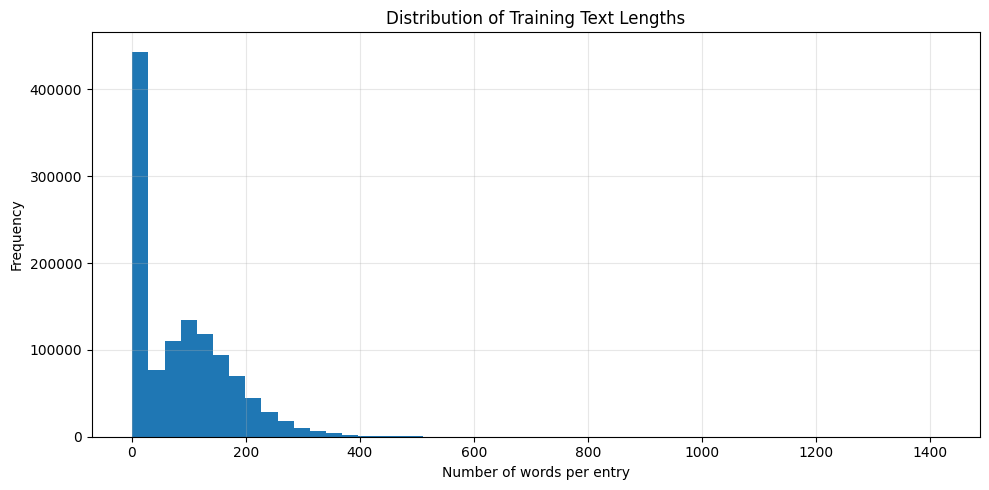


Processed dataset statistics:
test: 2,891 non-empty entries
train: 1,165,029 non-empty entries
validation: 2,461 non-empty entries
Saved: /content/drive/MyDrive/Mini-GPT-Project/data/processed/test.txt
Saved: /content/drive/MyDrive/Mini-GPT-Project/data/processed/train.txt
Saved: /content/drive/MyDrive/Mini-GPT-Project/data/processed/validation.txt

STEP 1 COMPLETED
test: True | 1.22 MB
train: True | 512.09 MB
validation: True | 1.09 MB

All processed datasets saved to Google Drive.


In [3]:

# ============================================================
# STEP 1 — DATASET PREPARATION AND EXPLORATION
# ============================================================

# 1. Imports

from datasets import load_dataset, DatasetDict
from pathlib import Path
import pandas as pd
import numpy as np
import json
import re
import matplotlib.pyplot as plt
import time

# Project paths
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


# 2. Download WikiText-103

print("Downloading WikiText-103...")

start_time = time.time()

dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-103-raw-v1"
)

download_time = time.time() - start_time

print("\nDataset downloaded successfully.")
print(f"Download time: {download_time:.2f} seconds")


# 3. Inspect dataset structure

print("\nDataset structure:")
print(dataset)

print("\nAvailable splits:")

for split in dataset.keys():
    print(
        f"{split}: {len(dataset[split]):,} examples"
    )


# 4. Save original dataset to Google Drive

raw_dataset_path = RAW_DIR / "wikitext-103"

dataset.save_to_disk(str(raw_dataset_path))

print("\nOriginal dataset saved to:")
print(raw_dataset_path)


# 5. Inspect representative examples

print("\nRepresentative training examples:\n")

for i in range(min(5, len(dataset["train"]))):

    text = dataset["train"][i]["text"]

    print(f"Example {i + 1}:")
    print(text[:500])
    print("-" * 60)


# 6. Dataset statistics

def get_dataset_statistics(split):

    texts = split["text"]

    non_empty = [
        text for text in texts
        if text.strip()
    ]

    character_counts = [
        len(text) for text in non_empty
    ]

    word_counts = [
        len(text.split()) for text in non_empty
    ]

    total_characters = sum(character_counts)
    total_words = sum(word_counts)

    return {
        "total_rows": len(texts),
        "non_empty_rows": len(non_empty),
        "empty_rows": len(texts) - len(non_empty),
        "total_characters": total_characters,
        "total_words": total_words,
        "average_characters": (
            np.mean(character_counts)
            if character_counts else 0
        ),
        "average_words": (
            np.mean(word_counts)
            if word_counts else 0
        )
    }


statistics = {}

for split_name in dataset.keys():

    statistics[split_name] = (
        get_dataset_statistics(dataset[split_name])
    )

statistics_df = pd.DataFrame(statistics).T

print("\nDataset statistics:")
display(statistics_df.round(2))

statistics_df.to_csv(
    PROCESSED_DIR / "dataset_statistics.csv"
)


# 7. Analyze text lengths

train_texts = dataset["train"]["text"]

train_lengths = [
    len(text.split())
    for text in train_texts
    if text.strip()
]

plt.figure(figsize=(10, 5))

plt.hist(
    train_lengths,
    bins=50
)

plt.title("Distribution of Training Text Lengths")
plt.xlabel("Number of words per entry")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROCESSED_DIR / "text_length_distribution.png",
    dpi=300
)

plt.show()


# 8. Data cleaning

def clean_text(text):

    # Remove leading and trailing whitespace
    text = text.strip()

    # Normalize repeated spaces
    text = re.sub(r"[ \t]+", " ", text)

    # Remove excessive blank lines
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text


def process_split(split):

    processed_texts = []

    for example in split:

        text = clean_text(example["text"])

        # Remove empty entries
        if not text:
            continue

        processed_texts.append(text)

    return processed_texts


# Preserve all three official splits
processed_data = {
    split_name: process_split(dataset[split_name])
    for split_name in dataset.keys()
}

print("\nProcessed dataset statistics:")

for split_name, texts in processed_data.items():

    print(
        f"{split_name}: "
        f"{len(texts):,} non-empty entries"
    )


# 9. Save processed text files

for split_name, texts in processed_data.items():

    output_path = (
        PROCESSED_DIR / f"{split_name}.txt"
    )

    with open(
        output_path,
        "w",
        encoding="utf-8"
    ) as file:

        for text in texts:
            file.write(text + "\n")

    print(f"Saved: {output_path}")


# 10. Save dataset processing metadata

metadata = {
    "dataset": "WikiText-103",
    "configuration": "wikitext-103-raw-v1",
    "source": "Salesforce/wikitext",
    "splits": {},
    "download_time_seconds": round(download_time, 2)
}

for split_name, texts in processed_data.items():

    metadata["splits"][split_name] = {
        "number_of_entries": len(texts),
        "total_characters": sum(map(len, texts)),
        "total_words": sum(
            len(text.split()) for text in texts
        )
    }

with open(
    PROCESSED_DIR / "dataset_metadata.json",
    "w"
) as file:

    json.dump(metadata, file, indent=4)


# 11. Final verification

print("\n" + "=" * 60)
print("STEP 1 COMPLETED")
print("=" * 60)

for split_name in processed_data:

    path = PROCESSED_DIR / f"{split_name}.txt"

    print(
        f"{split_name}: "
        f"{path.exists()} | "
        f"{path.stat().st_size / (1024**2):.2f} MB"
    )

print("\nAll processed datasets saved to Google Drive.")


# Step 2 — Train a Byte-Pair Encoding (BPE) Tokenizer

A language model cannot process raw text directly. It requires text to be converted into numerical token IDs.

In this project, we will implement a custom Byte-Pair Encoding (BPE) tokenizer using the Hugging Face Tokenizers library.

BPE starts with small text units and progressively merges frequent adjacent units into larger tokens. This allows the tokenizer to represent common words efficiently while retaining the ability to encode less common words.

We will train the tokenizer on the training split of WikiText-103 only. The validation and test splits will remain excluded from tokenizer training to preserve our evaluation protocol.

The tokenizer will use a target vocabulary of 8,000 tokens, including special tokens required for unknown text and sequence boundaries.

During this phase, we will:

- Train the tokenizer on the training text.
- Measure vocabulary size and tokenization statistics.
- Compare character, word and token counts.
- Inspect representative tokenization examples.
- Save the tokenizer and metadata to Google Drive.
- Reload the saved tokenizer and verify that it works.

**Expected outcome:** A reproducible BPE tokenizer that converts WikiText-103 text into token IDs for training our decoder-only Transformer.

Training file: /content/drive/MyDrive/Mini-GPT-Project/data/processed/train.txt
Target vocabulary size: 8,000

Training BPE tokenizer...

Tokenizer training time: 186.42 seconds

Actual vocabulary size: 8000
Special token IDs: {'[PAD]': 0, '[UNK]': 1, '[BOS]': 2, '[EOS]': 3}

Tokenizer saved to: /content/drive/MyDrive/Mini-GPT-Project/data/tokenizer/bpe_tokenizer.json

Tokenization examples:

Text: Transformers use self-attention to process sequences.
Tokens: ['T', 'rans', 'form', 'ers', 'Ġuse', 'Ġself', '-', 'att', 'ention', 'Ġto', 'Ġprocess', 'Ġsequ', 'ences', '.']
Token IDs: [55, 938, 686, 379, 1167, 3150, 16, 713, 1810, 293, 2097, 2635, 1512, 17]
Number of tokens: 14

Text: Artificial intelligence and machine learning.
Tokens: ['Ar', 't', 'ific', 'ial', 'Ġintelligence', 'Ġand', 'Ġmachine', 'Ġlearning', '.']
Token IDs: [5272, 87, 881, 476, 6749, 292, 4783, 7735, 17]
Number of tokens: 9

Text: The model predicts the next token in a sequence.
Tokens: ['The', 'Ġmodel', 'Ġpred', 'ic', '

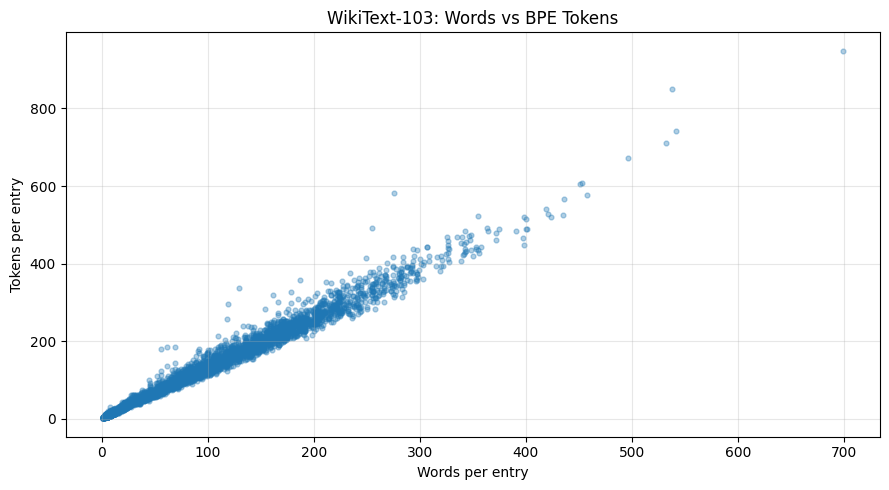


Metadata saved to: /content/drive/MyDrive/Mini-GPT-Project/data/tokenizer/tokenizer_metadata.json

Tokenizer reload verification: PASSED
Vocabulary size: 8000
Test token IDs: [36, 3073, 1810, 5936, 262, 3459, 293, 1167, 1437, 293, 78, 643, 17]

STEP 2 COMPLETED SUCCESSFULLY


In [4]:

# ============================================================
# STEP 2 — TRAIN A BPE TOKENIZER FROM SCRATCH
# ============================================================

from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from tokenizers import decoders, normalizers
from pathlib import Path
import json
import time
import numpy as np
import matplotlib.pyplot as plt

# 1. Paths and configuration

TOKENIZER_DIR = PROJECT_DIR / "data" / "tokenizer"
TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = PROJECT_DIR / "data" / "processed" / "train.txt"

TOKENIZER_PATH = TOKENIZER_DIR / "bpe_tokenizer.json"
TOKENIZER_METADATA_PATH = TOKENIZER_DIR / "tokenizer_metadata.json"

VOCAB_SIZE = 8000

assert TRAIN_FILE.exists(), (
    f"Training file not found: {TRAIN_FILE}. "
    "Finish Step 1 before continuing."
)

print("Training file:", TRAIN_FILE)
print(f"Target vocabulary size: {VOCAB_SIZE:,}")


# 2. Initialize BPE tokenizer

tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))

tokenizer.normalizer = normalizers.NFC()

tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)

tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=[
        "[PAD]",
        "[UNK]",
        "[BOS]",
        "[EOS]"
    ],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    show_progress=True
)


# 3. Train using the training split only

print("\nTraining BPE tokenizer...")

start_time = time.time()

tokenizer.train(
    files=[str(TRAIN_FILE)],
    trainer=trainer
)

training_time = time.time() - start_time

print(f"\nTokenizer training time: {training_time:.2f} seconds")


# 4. Configure special token IDs

vocab = tokenizer.get_vocab()

special_token_ids = {
    token: tokenizer.token_to_id(token)
    for token in ["[PAD]", "[UNK]", "[BOS]", "[EOS]"]
}

actual_vocab_size = tokenizer.get_vocab_size()

print("\nActual vocabulary size:", actual_vocab_size)
print("Special token IDs:", special_token_ids)


# 5. Save tokenizer permanently

tokenizer.save(str(TOKENIZER_PATH))

print("\nTokenizer saved to:", TOKENIZER_PATH)


# 6. Inspect representative examples

examples = [
    "Transformers use self-attention to process sequences.",
    "Artificial intelligence and machine learning.",
    "The model predicts the next token in a sequence."
]

print("\nTokenization examples:")

for text in examples:

    encoding = tokenizer.encode(text)

    print("\nText:", text)
    print("Tokens:", encoding.tokens)
    print("Token IDs:", encoding.ids)
    print("Number of tokens:", len(encoding.ids))


# 7. Measure tokenization statistics on a sample

# Use a bounded sample to keep this step efficient.
# This is for tokenizer diagnostics, not model evaluation.

SAMPLE_SIZE = 5000

sample_texts = []

with open(TRAIN_FILE, "r", encoding="utf-8") as file:

    for line in file:

        if line.strip():
            sample_texts.append(line.rstrip("\n"))

        if len(sample_texts) >= SAMPLE_SIZE:
            break

if not sample_texts:
    raise ValueError("No non-empty training text found.")

character_counts = []
word_counts = []
token_counts = []

for text in sample_texts:

    encoding = tokenizer.encode(text)

    character_counts.append(len(text))
    word_counts.append(len(text.split()))
    token_counts.append(len(encoding.ids))

statistics = {
    "sample_entries": len(sample_texts),
    "vocabulary_size": actual_vocab_size,
    "target_vocabulary_size": VOCAB_SIZE,
    "tokenizer_training_time_seconds": round(training_time, 2),
    "mean_characters_per_entry": float(np.mean(character_counts)),
    "mean_words_per_entry": float(np.mean(word_counts)),
    "mean_tokens_per_entry": float(np.mean(token_counts)),
    "tokens_per_word": float(
        sum(token_counts) / max(sum(word_counts), 1)
    ),
    "characters_per_token": float(
        sum(character_counts) / max(sum(token_counts), 1)
    ),
    "special_token_ids": special_token_ids
}

print("\nTokenization statistics:")

for key, value in statistics.items():
    print(f"{key}: {value}")


# 8. Plot text length versus token length

plt.figure(figsize=(9, 5))

plt.scatter(
    word_counts,
    token_counts,
    alpha=0.35,
    s=12
)

plt.xlabel("Words per entry")
plt.ylabel("Tokens per entry")
plt.title("WikiText-103: Words vs BPE Tokens")
plt.grid(alpha=0.3)
plt.tight_layout()

plot_path = PROJECT_DIR / "results" / "graphs" / "tokenizer_statistics.png"

plt.savefig(plot_path, dpi=300)
plt.show()


# 9. Save metadata

with open(TOKENIZER_METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(statistics, file, indent=4)

print("\nMetadata saved to:", TOKENIZER_METADATA_PATH)


# 10. Reload and verify tokenizer

reloaded_tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))

test_text = "Attention allows a model to use previous tokens."

original_ids = tokenizer.encode(test_text).ids
reloaded_ids = reloaded_tokenizer.encode(test_text).ids

assert original_ids == reloaded_ids, (
    "Tokenizer verification failed."
)

print("\nTokenizer reload verification: PASSED")
print("Vocabulary size:", reloaded_tokenizer.get_vocab_size())
print("Test token IDs:", reloaded_ids)

print("\nSTEP 2 COMPLETED SUCCESSFULLY")


# Step 3 — Implement the Mini-GPT Architecture

**Objective:** Build a small decoder-only Transformer from scratch using PyTorch. We will not load pretrained GPT weights.

The model will use the following initial configuration:

- Vocabulary size: 8,000 tokens
- Context length: 128 tokens
- Embedding dimension: 128
- Transformer layers: 4
- Attention heads: 4
- Dropout: 0.1

**What this step does:** implements causal self-attention, feed-forward networks, residual connections, positional embeddings, and next-token prediction. It then checks the output shape, parameter count, and that the model produces a valid loss.

**Expected output:** logits shaped `(batch_size, sequence_length, vocabulary_size)` and a finite loss. This verifies the architecture, not yet its ability to generate good text.

In [5]:

# Step 3 — Build and test Mini-GPT from scratch

import json
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from tokenizers import Tokenizer

# ---------- 1. Paths and configuration ----------

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
TOKENIZER_PATH = PROJECT_DIR / "data/tokenizer/bpe_tokenizer.json"
MODEL_DIR = PROJECT_DIR / "checkpoints/small_gpt"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

assert TOKENIZER_PATH.exists(), (
    f"Tokenizer not found: {TOKENIZER_PATH}. Complete Step 2 first."
)

tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
VOCAB_SIZE = tokenizer.get_vocab_size()

CONFIG = {
    "vocab_size": VOCAB_SIZE,
    "context_length": 128,
    "embedding_dim": 128,
    "num_layers": 4,
    "num_heads": 4,
    "dropout": 0.1,
    "bias": True,
}

assert CONFIG["embedding_dim"] % CONFIG["num_heads"] == 0

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Vocabulary size:", VOCAB_SIZE)


# ---------- 2. Causal self-attention ----------

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.num_heads = config["num_heads"]
        self.head_dim = dim // self.num_heads
        self.dropout = config["dropout"]

        self.qkv = nn.Linear(dim, 3 * dim, bias=config["bias"])
        self.proj = nn.Linear(dim, dim, bias=config["bias"])
        self.attn_dropout = nn.Dropout(self.dropout)
        self.resid_dropout = nn.Dropout(self.dropout)

        # A token can attend only to itself and earlier tokens.
        mask = torch.tril(
            torch.ones(
                config["context_length"],
                config["context_length"],
                dtype=torch.bool,
            )
        )
        self.register_buffer("causal_mask", mask, persistent=False)

    def forward(self, x):
        batch_size, seq_len, dim = x.shape

        q, k, v = self.qkv(x).chunk(3, dim=-1)

        # (batch, sequence, embedding) -> (batch, heads, sequence, head_dim)
        q = q.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        mask = self.causal_mask[:seq_len, :seq_len]
        scores = scores.masked_fill(~mask, float("-inf"))

        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)

        output = weights @ v
        output = output.transpose(1, 2).contiguous().view(batch_size, seq_len, dim)
        return self.resid_dropout(self.proj(output))


# ---------- 3. Feed-forward network ----------

class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.network = nn.Sequential(
            nn.Linear(dim, 4 * dim, bias=config["bias"]),
            nn.GELU(),
            nn.Linear(4 * dim, dim, bias=config["bias"]),
            nn.Dropout(config["dropout"]),
        )

    def forward(self, x):
        return self.network(x)


# ---------- 4. Transformer block ----------

class TransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.norm1 = nn.LayerNorm(dim)
        self.attention = CausalSelfAttention(config)
        self.norm2 = nn.LayerNorm(dim)
        self.feed_forward = FeedForward(config)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


# ---------- 5. Mini-GPT language model ----------

class MiniGPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config

        self.token_embedding = nn.Embedding(
            config["vocab_size"], config["embedding_dim"]
        )
        self.position_embedding = nn.Embedding(
            config["context_length"], config["embedding_dim"]
        )
        self.embedding_dropout = nn.Dropout(config["dropout"])

        self.blocks = nn.Sequential(
            *[TransformerBlock(config) for _ in range(config["num_layers"])]
        )
        self.final_norm = nn.LayerNorm(config["embedding_dim"])
        self.lm_head = nn.Linear(
            config["embedding_dim"], config["vocab_size"], bias=False
        )

        # Share input token embeddings and output projection weights.
        self.lm_head.weight = self.token_embedding.weight

        self.apply(self._initialize_weights)

    @staticmethod
    def _initialize_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None):
        batch_size, seq_len = input_ids.shape

        if seq_len > self.config["context_length"]:
            raise ValueError(
                f"Sequence length {seq_len} exceeds context length "
                f"{self.config['context_length']}."
            )

        positions = torch.arange(seq_len, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.embedding_dropout(x)
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1),
            )

        return logits, loss


# ---------- 6. Instantiate and test ----------

model = MiniGPT(CONFIG).to(DEVICE)

# Example batch: 4 sequences, each containing 32 token IDs.
batch_size = 4
sequence_length = 32

input_ids = torch.randint(
    0, VOCAB_SIZE, (batch_size, sequence_length), device=DEVICE
)
targets = torch.randint(
    0, VOCAB_SIZE, (batch_size, sequence_length), device=DEVICE
)

model.eval()
with torch.no_grad():
    logits, test_loss = model(input_ids, targets)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\n--- Architecture test ---")
print("Input shape:", tuple(input_ids.shape))
print("Logits shape:", tuple(logits.shape))
print("Expected logits shape:", (batch_size, sequence_length, VOCAB_SIZE))
print("Test loss:", round(test_loss.item(), 4))
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

assert logits.shape == (batch_size, sequence_length, VOCAB_SIZE)
assert torch.isfinite(test_loss).item()
assert total_params == trainable_params

# Save configuration and initial weights to persistent Google Drive storage.
with open(MODEL_DIR / "model_config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "config": CONFIG,
        "seed": SEED,
        "note": "Initial untrained weights; not a trained language model.",
    },
    MODEL_DIR / "initial_model.pt",
)

print("\nConfiguration saved:", MODEL_DIR / "model_config.json")
print("Initial weights saved:", MODEL_DIR / "initial_model.pt")
print("STEP 3 COMPLETED SUCCESSFULLY")


Device: cuda
Vocabulary size: 8000

--- Architecture test ---
Input shape: (4, 32)
Logits shape: (4, 32, 8000)
Expected logits shape: (4, 32, 8000)
Test loss: 9.0021
Total parameters: 1,833,728
Trainable parameters: 1,833,728

Configuration saved: /content/drive/MyDrive/Mini-GPT-Project/checkpoints/small_gpt/model_config.json
Initial weights saved: /content/drive/MyDrive/Mini-GPT-Project/checkpoints/small_gpt/initial_model.pt
STEP 3 COMPLETED SUCCESSFULLY


# Step 4 — Prepare tokenized data and train a bigram baseline
### Objective

Prepare the WikiText dataset for next-token prediction and train a simple **bigram language model** as a baseline.

A bigram model predicts the next token using only the current token. Your Mini-GPT can use a longer context, so the baseline helps measure whether the Transformer learns useful additional context.

This step will:
- Load the saved tokenizer and processed text files.
- Convert the training, validation, and test text into token IDs.
- Save token IDs to Google Drive.
- Train the bigram model with periodic checkpoints.
- Record training and validation loss.

The test split will be kept for final evaluation, not used for training or model selection.

In [6]:

# Step 4 — Tokenize WikiText and train a bigram baseline

import json
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from tokenizers import Tokenizer

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
TOKENIZER_PATH = PROJECT_DIR / "data/tokenizer/bpe_tokenizer.json"
DATA_DIR = PROJECT_DIR / "data/processed"
BIGRAM_DIR = PROJECT_DIR / "checkpoints/bigram"
RESULTS_DIR = PROJECT_DIR / "results/metrics"

BIGRAM_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------- 1. Check files ----------

for split in ("train", "validation", "test"):
    path = DATA_DIR / f"{split}.txt"
    assert path.exists(), (
        f"Missing {path}. Check that Step 1 completed successfully."
    )

assert TOKENIZER_PATH.exists(), "Tokenizer file not found. Complete Step 2 first."

tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
VOCAB_SIZE = tokenizer.get_vocab_size()

# ---------- 2. Convert each split to token IDs ----------

def encode_text_file(path, output_path, chunk_size=100_000):
    """Encode a text file in chunks and save token IDs as an int32 NumPy array."""
    import numpy as np

    all_ids = []
    text_buffer = []
    total_chars = 0

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                text_buffer.append(line.strip())
                total_chars += len(line)

            if sum(len(s) for s in text_buffer) >= chunk_size:
                encoded = tokenizer.encode("\n".join(text_buffer))
                all_ids.extend(encoded.ids)
                text_buffer = []

    if text_buffer:
        encoded = tokenizer.encode("\n".join(text_buffer))
        all_ids.extend(encoded.ids)

    token_array = np.asarray(all_ids, dtype=np.int32)
    np.save(output_path, token_array)

    return {
        "tokens": int(len(token_array)),
        "characters": int(total_chars),
        "file": str(output_path),
    }

# Process one split at a time to limit peak memory.
token_data = {}
for split in ("train", "validation", "test"):
    source = DATA_DIR / f"{split}.txt"
    destination = DATA_DIR / f"{split}_tokens.npy"

    print(f"\nEncoding {split} split...")
    start = time.time()
    info = encode_text_file(source, destination)
    info["encoding_seconds"] = round(time.time() - start, 2)
    token_data[split] = info

    print("Token count:", f"{info['tokens']:,}")
    print("Encoding time:", info["encoding_seconds"], "seconds")
    print("Saved:", destination)

with open(DATA_DIR / "tokenization_summary.json", "w", encoding="utf-8") as f:
    json.dump(token_data, f, indent=2)

# ---------- 3. Define a bigram model ----------

class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # Each current token directly predicts a distribution over next tokens.
        self.token_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, input_ids, targets=None):
        logits = self.token_table(input_ids)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1),
            )
        return logits, loss


# ---------- 4. Load token arrays and create batches ----------

import numpy as np

train_ids = np.load(DATA_DIR / "train_tokens.npy", mmap_mode="r")
val_ids = np.load(DATA_DIR / "validation_tokens.npy", mmap_mode="r")

CONTEXT_LENGTH = 128
BATCH_SIZE = 128
MAX_STEPS = 3000
EVAL_EVERY = 250
CHECKPOINT_EVERY = 500
LEARNING_RATE = 3e-3

def get_batch(token_array, batch_size, context_length, device):
    max_start = len(token_array) - context_length - 1
    if max_start <= 0:
        raise ValueError("Not enough tokens to create a training batch.")

    starts = torch.randint(0, max_start, (batch_size,)).tolist()

    x = np.stack([
        np.asarray(token_array[s:s + context_length], dtype=np.int64)
        for s in starts
    ])
    y = np.stack([
        np.asarray(token_array[s + 1:s + context_length + 1], dtype=np.int64)
        for s in starts
    ])

    return (
        torch.from_numpy(x).to(device),
        torch.from_numpy(y).to(device),
    )

# ---------- 5. Initialize or resume training ----------

model = BigramLanguageModel(VOCAB_SIZE).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

checkpoint_path = BIGRAM_DIR / "latest_checkpoint.pt"
history_path = RESULTS_DIR / "bigram_training_history.json"
history = {"step": [], "train_loss": [], "validation_loss": []}
start_step = 0

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_step = checkpoint["step"]

    if history_path.exists():
        with open(history_path, "r", encoding="utf-8") as f:
            history = json.load(f)

    print(f"Resuming from step {start_step}.")
else:
    print("Starting new bigram training run.")

@torch.no_grad()
def estimate_loss():
    model.eval()
    losses = {}

    for split_name, array in (("train", train_ids), ("validation", val_ids)):
        batch_losses = []
        for _ in range(10):
            x, y = get_batch(array, BATCH_SIZE, CONTEXT_LENGTH, DEVICE)
            _, loss = model(x, y)
            batch_losses.append(loss.item())
        losses[split_name] = float(np.mean(batch_losses))

    model.train()
    return losses

# ---------- 6. Train with Drive checkpoints ----------

start_time = time.time()
model.train()

for step in range(start_step + 1, MAX_STEPS + 1):
    x, y = get_batch(train_ids, BATCH_SIZE, CONTEXT_LENGTH, DEVICE)
    _, loss = model(x, y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if step % EVAL_EVERY == 0 or step == 1:
        metrics = estimate_loss()
        history["step"].append(step)
        history["train_loss"].append(metrics["train"])
        history["validation_loss"].append(metrics["validation"])

        print(
            f"Step {step:4d}/{MAX_STEPS} | "
            f"train loss: {metrics['train']:.4f} | "
            f"validation loss: {metrics['validation']:.4f}"
        )

    if step % CHECKPOINT_EVERY == 0 or step == MAX_STEPS:
        torch.save(
            {
                "step": step,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "config": {
                    "vocab_size": VOCAB_SIZE,
                    "context_length": CONTEXT_LENGTH,
                    "batch_size": BATCH_SIZE,
                    "learning_rate": LEARNING_RATE,
                    "max_steps": MAX_STEPS,
                },
                "history": history,
            },
            checkpoint_path,
        )

        with open(history_path, "w", encoding="utf-8") as f:
            json.dump(history, f, indent=2)

        print("Checkpoint saved at step", step)

elapsed = time.time() - start_time

# Save final model separately.
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocab_size": VOCAB_SIZE,
        "context_length": CONTEXT_LENGTH,
        "training_steps": MAX_STEPS,
        "history": history,
    },
    BIGRAM_DIR / "bigram_final.pt",
)

print("\nTraining time:", round(elapsed, 2), "seconds")
print("Final model:", BIGRAM_DIR / "bigram_final.pt")
print("Training history:", history_path)
print("STEP 4 COMPLETED SUCCESSFULLY")



Encoding train split...
Token count: 135,701,334
Encoding time: 408.97 seconds
Saved: /content/drive/MyDrive/Mini-GPT-Project/data/processed/train_tokens.npy

Encoding validation split...
Token count: 283,581
Encoding time: 1.32 seconds
Saved: /content/drive/MyDrive/Mini-GPT-Project/data/processed/validation_tokens.npy

Encoding test split...
Token count: 324,085
Encoding time: 1.43 seconds
Saved: /content/drive/MyDrive/Mini-GPT-Project/data/processed/test_tokens.npy
Resuming from step 3000.

Training time: 0.0 seconds
Final model: /content/drive/MyDrive/Mini-GPT-Project/checkpoints/bigram/bigram_final.pt
Training history: /content/drive/MyDrive/Mini-GPT-Project/results/metrics/bigram_training_history.json
STEP 4 COMPLETED SUCCESSFULLY


#Step 5 — Train Mini-GPT from scratch
### Objective

Train the 1.83M-parameter decoder-only Transformer implemented in Step 3 using the WikiText training split.

The model learns next-token prediction: given a sequence of tokens, it predicts the next token at each position. We will use the same vocabulary and context length as the bigram baseline.

**Configuration**
- Context length: 128 tokens
- Embedding dimension: 128
- Transformer layers: 4
- Attention heads: 4
- Batch size: 32
- Learning rate: 0.0003
- Training budget: 3,000 steps initially
- Checkpoint interval: 500 steps

The code resumes from the latest checkpoint if one exists, evaluates sampled training and validation batches, and saves the model and training history to Google Drive. The test split remains untouched until final evaluation.

In [7]:

# Step 5 — Train Mini-GPT with checkpointing

import json
import time
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
DATA_DIR = PROJECT_DIR / "data/processed"
MODEL_DIR = PROJECT_DIR / "checkpoints/small_gpt"
RESULTS_DIR = PROJECT_DIR / "results/metrics"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------- 1. Configuration ----------

with open(MODEL_DIR / "model_config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

VOCAB_SIZE = CONFIG["vocab_size"]
CONTEXT_LENGTH = CONFIG["context_length"]
BATCH_SIZE = 32
MAX_STEPS = 3000
EVAL_EVERY = 250
CHECKPOINT_EVERY = 500
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0

# ---------- 2. Load token IDs ----------

train_ids = np.load(DATA_DIR / "train_tokens.npy", mmap_mode="r")
val_ids = np.load(DATA_DIR / "validation_tokens.npy", mmap_mode="r")

print("Device:", DEVICE)
print("Training tokens:", f"{len(train_ids):,}")
print("Validation tokens:", f"{len(val_ids):,}")
print("Vocabulary:", VOCAB_SIZE)
print("Context length:", CONTEXT_LENGTH)

def get_batch(token_array, batch_size, context_length, device):
    max_start = len(token_array) - context_length - 1
    if max_start <= 0:
        raise ValueError("Not enough tokens for the requested context length.")

    starts = torch.randint(0, max_start, (batch_size,)).tolist()

    x = np.stack([
        np.asarray(token_array[s:s + context_length], dtype=np.int64)
        for s in starts
    ])
    y = np.stack([
        np.asarray(token_array[s + 1:s + context_length + 1], dtype=np.int64)
        for s in starts
    ])

    return torch.from_numpy(x).to(device), torch.from_numpy(y).to(device)


# ---------- 3. Define the GPT architecture ----------

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.num_heads = config["num_heads"]
        self.head_dim = dim // self.num_heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=True)
        self.proj = nn.Linear(dim, dim, bias=True)
        self.attn_dropout = nn.Dropout(config["dropout"])
        self.resid_dropout = nn.Dropout(config["dropout"])

        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(
                config["context_length"],
                config["context_length"],
                dtype=torch.bool,
            )),
            persistent=False,
        )

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)

        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(
            ~self.causal_mask[:T, :T], float("-inf")
        )
        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)

        out = weights @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.network = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.GELU(),
            nn.Linear(4 * dim, dim),
            nn.Dropout(config["dropout"]),
        )

    def forward(self, x):
        return self.network(x)


class TransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.norm1 = nn.LayerNorm(dim)
        self.attention = CausalSelfAttention(config)
        self.norm2 = nn.LayerNorm(dim)
        self.feed_forward = FeedForward(config)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.config = config

        self.token_embedding = nn.Embedding(config["vocab_size"], dim)
        self.position_embedding = nn.Embedding(
            config["context_length"], dim
        )
        self.embedding_dropout = nn.Dropout(config["dropout"])
        self.blocks = nn.Sequential(*[
            TransformerBlock(config)
            for _ in range(config["num_layers"])
        ])
        self.final_norm = nn.LayerNorm(dim)
        self.lm_head = nn.Linear(dim, config["vocab_size"], bias=False)

        # Tie token input embeddings and output projection weights.
        self.lm_head.weight = self.token_embedding.weight
        self.apply(self._initialize_weights)

    @staticmethod
    def _initialize_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None):
        B, T = input_ids.shape
        if T > self.config["context_length"]:
            raise ValueError("Input sequence exceeds the configured context length.")

        positions = torch.arange(T, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.embedding_dropout(x)
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1),
            )
        return logits, loss


# ---------- 4. Initialize model and optimizer ----------

model = MiniGPT(CONFIG).to(DEVICE)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

checkpoint_path = MODEL_DIR / "latest_checkpoint.pt"
history_path = RESULTS_DIR / "small_gpt_training_history.json"
history = {"step": [], "train_loss": [], "validation_loss": []}
start_step = 0

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_step = int(checkpoint["step"])

    if history_path.exists():
        with open(history_path, "r", encoding="utf-8") as f:
            history = json.load(f)

    print(f"Resuming from step {start_step}.")
else:
    print("Starting training from the initial weights.")
    initial_path = MODEL_DIR / "initial_model.pt"
    if initial_path.exists():
        initial = torch.load(
            initial_path, map_location=DEVICE, weights_only=False
        )
        model.load_state_dict(initial["model_state_dict"])
        print("Loaded Step 3 initial weights.")

# ---------- 5. Estimate loss on sampled batches ----------

@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}

    for split, token_array in (
        ("train", train_ids),
        ("validation", val_ids),
    ):
        batch_losses = []
        for _ in range(10):
            x, y = get_batch(
                token_array, BATCH_SIZE, CONTEXT_LENGTH, DEVICE
            )
            _, loss = model(x, y)
            batch_losses.append(loss.item())

        results[split] = float(np.mean(batch_losses))

    model.train()
    return results


# ---------- 6. Train and save checkpoints ----------

model.train()
start_time = time.time()

for step in range(start_step + 1, MAX_STEPS + 1):
    x, y = get_batch(train_ids, BATCH_SIZE, CONTEXT_LENGTH, DEVICE)
    _, loss = model(x, y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    optimizer.step()

    if step % EVAL_EVERY == 0 or step == 1:
        metrics = estimate_loss()
        history["step"].append(step)
        history["train_loss"].append(metrics["train"])
        history["validation_loss"].append(metrics["validation"])

        print(
            f"Step {step:4d}/{MAX_STEPS} | "
            f"train loss: {metrics['train']:.4f} | "
            f"validation loss: {metrics['validation']:.4f}"
        )

    if step % CHECKPOINT_EVERY == 0 or step == MAX_STEPS:
        torch.save(
            {
                "step": step,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "config": CONFIG,
                "history": history,
            },
            checkpoint_path,
        )

        with open(history_path, "w", encoding="utf-8") as f:
            json.dump(history, f, indent=2)

        print("Checkpoint saved at step", step)

elapsed = time.time() - start_time

# Save final checkpoint separately.
torch.save(
    {
        "step": MAX_STEPS,
        "model_state_dict": model.state_dict(),
        "config": CONFIG,
        "history": history,
    },
    MODEL_DIR / "small_gpt_final.pt",
)

with open(MODEL_DIR / "training_config.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "batch_size": BATCH_SIZE,
            "max_steps": MAX_STEPS,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "gradient_clip": GRAD_CLIP,
            "seed": SEED,
            "training_seconds": round(elapsed, 2),
        },
        f,
        indent=2,
    )

print("\nTraining time:", round(elapsed, 2), "seconds")
print("Final model:", MODEL_DIR / "small_gpt_final.pt")
print("History:", history_path)
print("STEP 5 COMPLETED SUCCESSFULLY")


Device: cuda
Training tokens: 135,701,334
Validation tokens: 283,581
Vocabulary: 8000
Context length: 128
Resuming from step 3000.

Training time: 0.0 seconds
Final model: /content/drive/MyDrive/Mini-GPT-Project/checkpoints/small_gpt/small_gpt_final.pt
History: /content/drive/MyDrive/Mini-GPT-Project/results/metrics/small_gpt_training_history.json
STEP 5 COMPLETED SUCCESSFULLY


#Step 6 — Evaluate and compare the models
### Objective

Evaluate the trained bigram baseline and Mini-GPT using the same held-out test dataset.

We will calculate:

- **Cross-entropy loss:** measures next-token prediction error.
- **Perplexity:** loss, measuring how uncertain the model is about the next token.
- **Next-token accuracy:** the percentage of predictions where the highest-probability token matches the target.
- **Parameter count:** the number of model parameters.
- **Training curves:** plots of training and validation loss across training steps.

We will also save the evaluation results and figures to Google Drive for the research report.

**Important:** The bigram and Mini-GPT have different architectures, so their losses must be calculated using the same test tokens and evaluation method. This step evaluates the existing models; it does not retrain them.

Device: cuda
Test tokens: 324,085
Evaluation context length: 128

Evaluating bigram...
Test cross-entropy: 5.6649
Test perplexity: 288.5638
Next-token accuracy: 14.78%
Parameters: 64,000,000
Evaluation time: 0.36 seconds

Evaluating mini_gpt...
Test cross-entropy: 5.1073
Test perplexity: 165.2242
Next-token accuracy: 18.90%
Parameters: 1,833,728
Evaluation time: 0.88 seconds


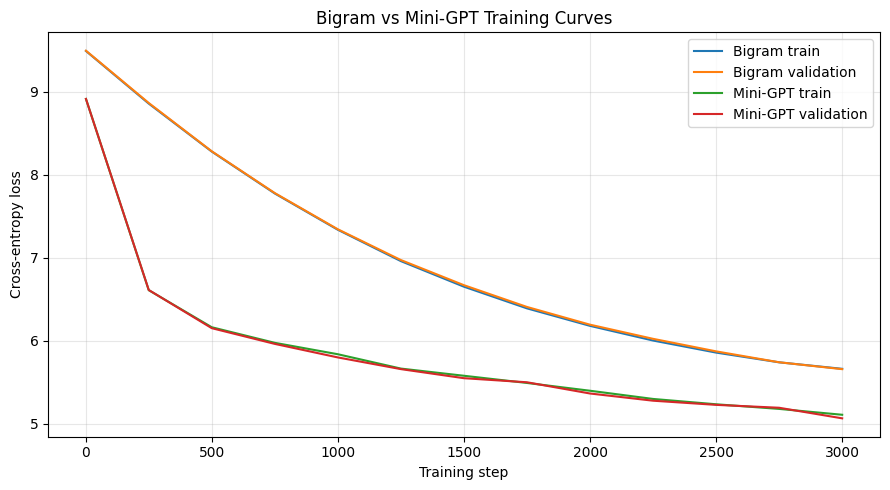


Saved test results: /content/drive/MyDrive/Mini-GPT-Project/results/metrics/model_comparison_test.json
Saved loss plot: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/bigram_vs_mini_gpt_loss.png
STEP 6 COMPLETED SUCCESSFULLY


In [8]:

# Step 6 — Evaluate Bigram vs Mini-GPT on the same test tokens

import json
import math
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
DATA_DIR = PROJECT_DIR / "data/processed"
BIGRAM_DIR = PROJECT_DIR / "checkpoints/bigram"
GPT_DIR = PROJECT_DIR / "checkpoints/small_gpt"
RESULTS_DIR = PROJECT_DIR / "results/metrics"
GRAPHS_DIR = PROJECT_DIR / "results/graphs"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# ---------- 1. Load saved model configurations ----------

with open(GPT_DIR / "model_config.json", "r", encoding="utf-8") as f:
    GPT_CONFIG = json.load(f)

bigram_checkpoint = torch.load(
    BIGRAM_DIR / "bigram_final.pt",
    map_location=DEVICE,
    weights_only=False,
)
gpt_checkpoint = torch.load(
    GPT_DIR / "small_gpt_final.pt",
    map_location=DEVICE,
    weights_only=False,
)

VOCAB_SIZE = GPT_CONFIG["vocab_size"]
CONTEXT_LENGTH = GPT_CONFIG["context_length"]

# ---------- 2. Recreate the model architectures ----------

class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, input_ids):
        return self.token_table(input_ids)


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.num_heads = config["num_heads"]
        self.head_dim = dim // self.num_heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=True)
        self.proj = nn.Linear(dim, dim, bias=True)
        self.attn_dropout = nn.Dropout(config["dropout"])
        self.resid_dropout = nn.Dropout(config["dropout"])
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(
                config["context_length"],
                config["context_length"],
                dtype=torch.bool,
            )),
            persistent=False,
        )

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(
            ~self.causal_mask[:T, :T], float("-inf")
        )
        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)
        out = weights @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.network = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.GELU(),
            nn.Linear(4 * dim, dim),
            nn.Dropout(config["dropout"]),
        )

    def forward(self, x):
        return self.network(x)


class TransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.norm1 = nn.LayerNorm(dim)
        self.attention = CausalSelfAttention(config)
        self.norm2 = nn.LayerNorm(dim)
        self.feed_forward = FeedForward(config)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        dim = config["embedding_dim"]
        self.config = config
        self.token_embedding = nn.Embedding(config["vocab_size"], dim)
        self.position_embedding = nn.Embedding(
            config["context_length"], dim
        )
        self.embedding_dropout = nn.Dropout(config["dropout"])
        self.blocks = nn.Sequential(*[
            TransformerBlock(config) for _ in range(config["num_layers"])
        ])
        self.final_norm = nn.LayerNorm(dim)
        self.lm_head = nn.Linear(dim, config["vocab_size"], bias=False)
        self.lm_head.weight = self.token_embedding.weight
        self.apply(self._initialize_weights)

    @staticmethod
    def _initialize_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids):
        B, T = input_ids.shape
        if T > self.config["context_length"]:
            raise ValueError("Sequence exceeds context length.")
        positions = torch.arange(T, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.embedding_dropout(x)
        x = self.blocks(x)
        x = self.final_norm(x)
        return self.lm_head(x)


bigram = BigramLanguageModel(VOCAB_SIZE).to(DEVICE)
bigram.load_state_dict(bigram_checkpoint["model_state_dict"])
bigram.eval()

gpt = MiniGPT(GPT_CONFIG).to(DEVICE)
gpt.load_state_dict(gpt_checkpoint["model_state_dict"])
gpt.eval()

# ---------- 3. Load held-out test tokens ----------

test_ids = np.load(DATA_DIR / "test_tokens.npy", mmap_mode="r")

print("Device:", DEVICE)
print("Test tokens:", f"{len(test_ids):,}")
print("Evaluation context length:", CONTEXT_LENGTH)

# Evaluate consecutive test tokens in non-overlapping blocks.
# Each target token is scored once; the first token is context only.
EVAL_BATCH_SIZE = 16

@torch.no_grad()
def evaluate_model(model, test_array, context_length, batch_size):
    total_loss = 0.0
    total_correct = 0
    total_targets = 0

    # Non-overlapping blocks: context tokens predict the following tokens.
    # Block boundaries do not receive context from the preceding block.
    n_blocks = (len(test_array) - 1) // context_length

    for block_start in range(0, n_blocks, batch_size):
        starts = range(
            block_start,
            min(block_start + batch_size, n_blocks)
        )

        xs, ys = [], []
        for block_idx in starts:
            start = block_idx * context_length
            x = np.asarray(
                test_array[start:start + context_length],
                dtype=np.int64,
            )
            y = np.asarray(
                test_array[start + 1:start + context_length + 1],
                dtype=np.int64,
            )
            xs.append(x)
            ys.append(y)

        x = torch.from_numpy(np.stack(xs)).to(DEVICE)
        y = torch.from_numpy(np.stack(ys)).to(DEVICE)

        logits = model(x)
        losses = F.cross_entropy(
            logits.reshape(-1, VOCAB_SIZE),
            y.reshape(-1),
            reduction="sum",
        )
        total_loss += losses.item()
        total_correct += (logits.argmax(dim=-1) == y).sum().item()
        total_targets += y.numel()

    mean_loss = total_loss / total_targets
    return {
        "test_cross_entropy": mean_loss,
        "test_perplexity": math.exp(min(mean_loss, 50)),
        "test_next_token_accuracy": total_correct / total_targets,
        "evaluated_targets": total_targets,
    }

# ---------- 4. Evaluate both models ----------

evaluation_results = {}

for name, model in (("bigram", bigram), ("mini_gpt", gpt)):
    print(f"\nEvaluating {name}...")
    start = time.time()
    result = evaluate_model(
        model, test_ids, CONTEXT_LENGTH, EVAL_BATCH_SIZE
    )
    result["parameter_count"] = sum(
        p.numel() for p in model.parameters()
    )
    result["evaluation_seconds"] = round(time.time() - start, 2)
    evaluation_results[name] = result

    print("Test cross-entropy:", round(result["test_cross_entropy"], 4))
    print("Test perplexity:", round(result["test_perplexity"], 4))
    print(
        "Next-token accuracy:",
        f"{100 * result['test_next_token_accuracy']:.2f}%"
    )
    print("Parameters:", f"{result['parameter_count']:,}")
    print("Evaluation time:", result["evaluation_seconds"], "seconds")

results_path = RESULTS_DIR / "model_comparison_test.json"
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(evaluation_results, f, indent=2)

# ---------- 5. Plot training and validation curves ----------

def load_history(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

bigram_history_path = RESULTS_DIR / "bigram_training_history.json"
gpt_history_path = RESULTS_DIR / "small_gpt_training_history.json"

bigram_history = load_history(bigram_history_path)
gpt_history = load_history(gpt_history_path)

plt.figure(figsize=(9, 5))
plt.plot(
    bigram_history["step"], bigram_history["train_loss"],
    label="Bigram train"
)
plt.plot(
    bigram_history["step"], bigram_history["validation_loss"],
    label="Bigram validation"
)
plt.plot(
    gpt_history["step"], gpt_history["train_loss"],
    label="Mini-GPT train"
)
plt.plot(
    gpt_history["step"], gpt_history["validation_loss"],
    label="Mini-GPT validation"
)
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Bigram vs Mini-GPT Training Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

curve_path = GRAPHS_DIR / "bigram_vs_mini_gpt_loss.png"
plt.savefig(curve_path, dpi=160)
plt.show()

print("\nSaved test results:", results_path)
print("Saved loss plot:", curve_path)
print("STEP 6 COMPLETED SUCCESSFULLY")


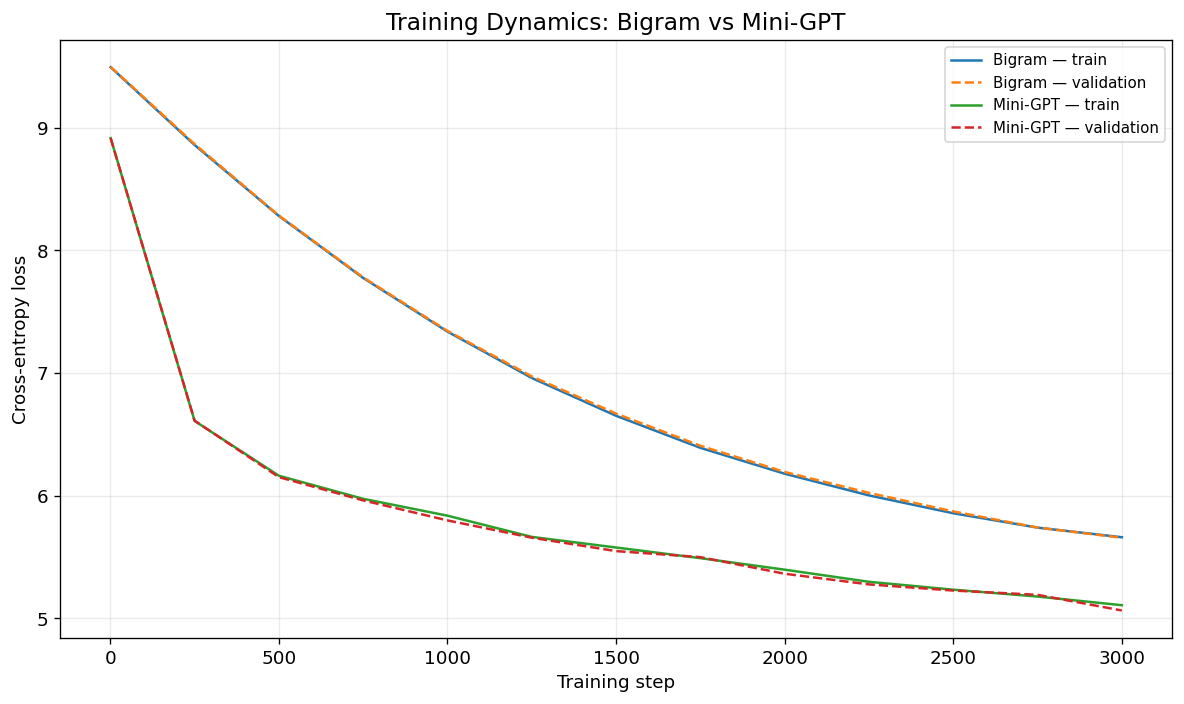

Saved: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/01_training_dynamics.png


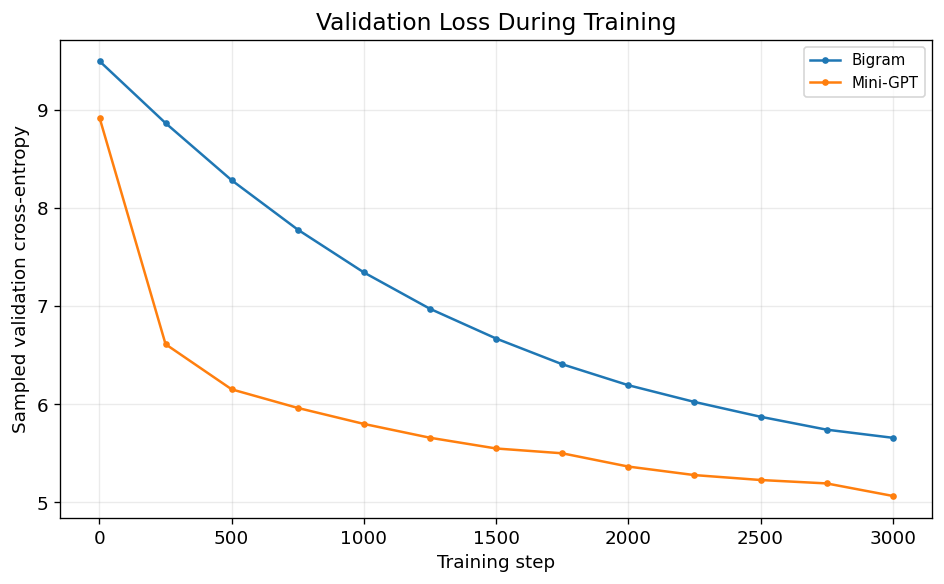

Saved: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/02_validation_loss.png


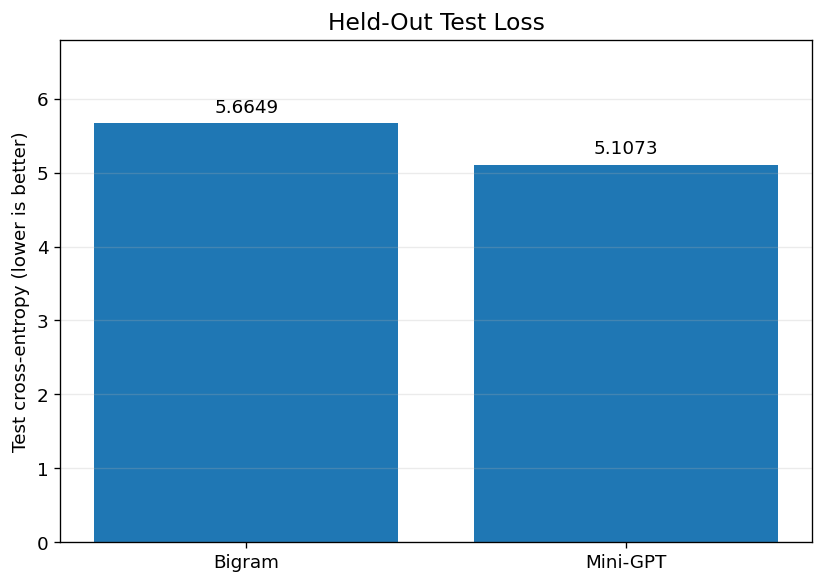

Saved: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/03_test_cross_entropy.png


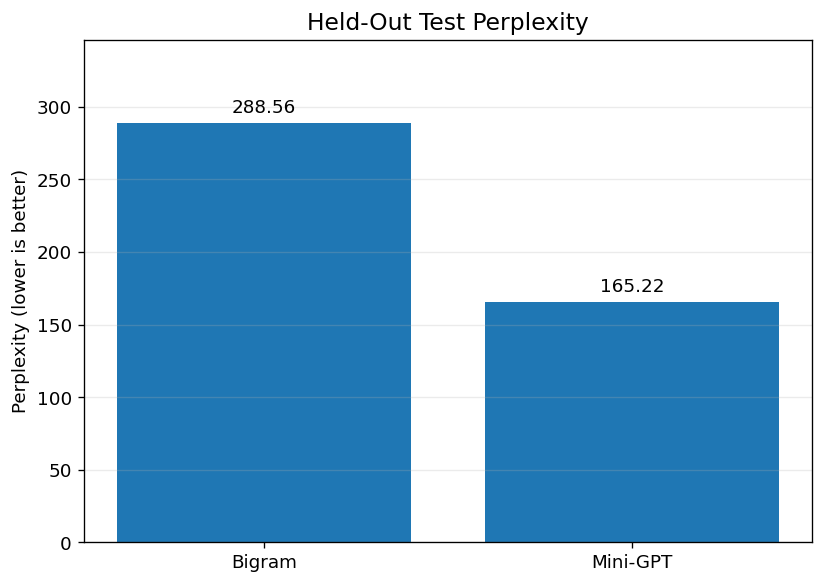

Saved: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/04_test_perplexity.png


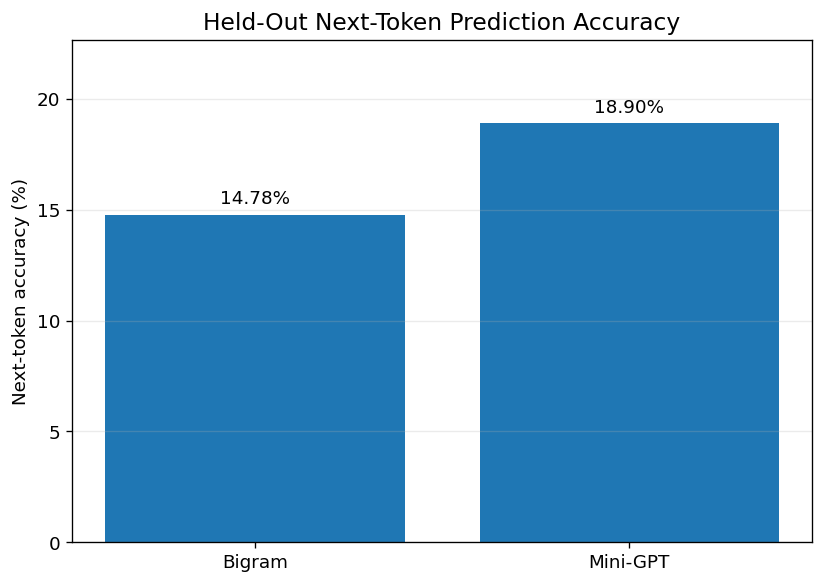

Saved: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/05_next_token_accuracy.png


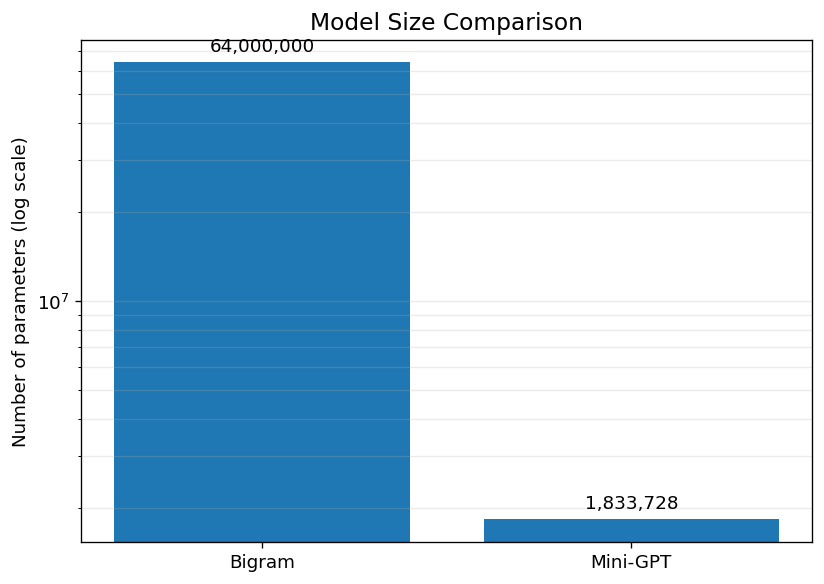

Saved: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/06_parameter_count.png


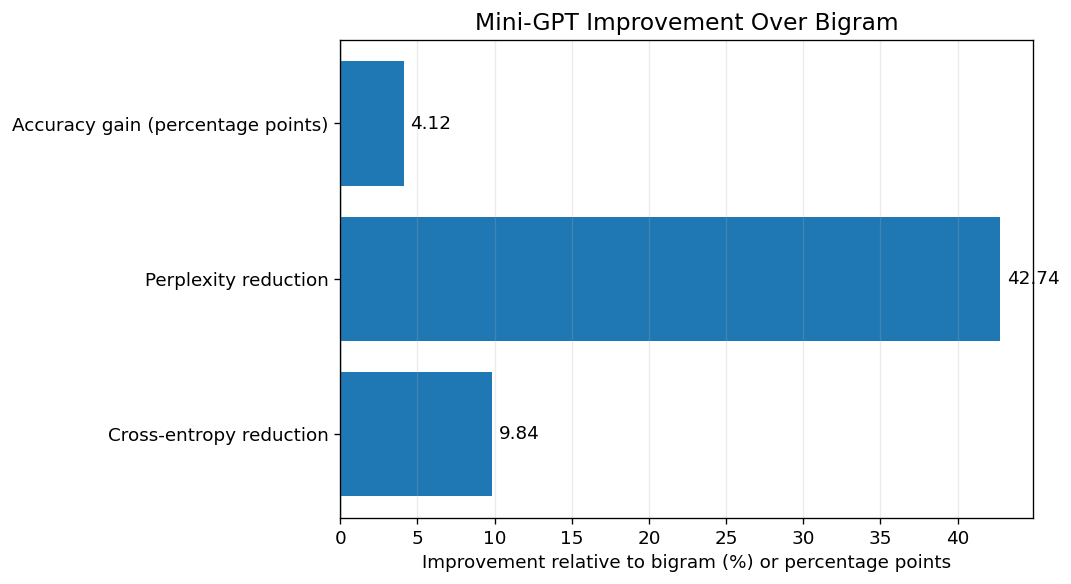

Saved: /content/drive/MyDrive/Mini-GPT-Project/results/graphs/07_relative_improvement.png

Relative improvements:
Cross-entropy reduction: 9.84%
Perplexity reduction: 42.74%
Accuracy gain: 4.12 percentage points

Comparison CSV saved: /content/drive/MyDrive/Mini-GPT-Project/results/metrics/model_comparison_summary.csv

STEP 6B COMPLETED SUCCESSFULLY


In [9]:

# Step 6B — Create research-style plots and comparison tables

import json
import csv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
RESULTS_DIR = PROJECT_DIR / "results/metrics"
GRAPHS_DIR = PROJECT_DIR / "results/graphs"
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

# ---------- 1. Load actual results ----------

with open(RESULTS_DIR / "model_comparison_test.json", "r") as f:
    test_results = json.load(f)

with open(RESULTS_DIR / "bigram_training_history.json", "r") as f:
    bigram_history = json.load(f)

with open(RESULTS_DIR / "small_gpt_training_history.json", "r") as f:
    gpt_history = json.load(f)

models = ["Bigram", "Mini-GPT"]
keys = ["bigram", "mini_gpt"]

# Consistent, readable plot defaults.
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

def save_figure(filename):
    path = GRAPHS_DIR / filename
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", path)

# ---------- Plot 1: Training and validation curves ----------

plt.figure(figsize=(10, 6))

plt.plot(
    bigram_history["step"],
    bigram_history["train_loss"],
    label="Bigram — train",
    linestyle="-",
)
plt.plot(
    bigram_history["step"],
    bigram_history["validation_loss"],
    label="Bigram — validation",
    linestyle="--",
)
plt.plot(
    gpt_history["step"],
    gpt_history["train_loss"],
    label="Mini-GPT — train",
    linestyle="-",
)
plt.plot(
    gpt_history["step"],
    gpt_history["validation_loss"],
    label="Mini-GPT — validation",
    linestyle="--",
)

plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Training Dynamics: Bigram vs Mini-GPT")
plt.grid(True, alpha=0.25)
plt.legend()
save_figure("01_training_dynamics.png")

# ---------- Plot 2: Validation loss comparison ----------

plt.figure(figsize=(8, 5))

for label, history in [
    ("Bigram", bigram_history),
    ("Mini-GPT", gpt_history),
]:
    plt.plot(
        history["step"],
        history["validation_loss"],
        marker="o",
        markersize=3,
        label=label,
    )

plt.xlabel("Training step")
plt.ylabel("Sampled validation cross-entropy")
plt.title("Validation Loss During Training")
plt.grid(True, alpha=0.25)
plt.legend()
save_figure("02_validation_loss.png")

# ---------- Plot 3: Test cross-entropy ----------

values = [test_results[k]["test_cross_entropy"] for k in keys]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, values)

plt.ylabel("Test cross-entropy (lower is better)")
plt.title("Held-Out Test Loss")
plt.bar_label(bars, fmt="%.4f", padding=4)
plt.ylim(0, max(values) * 1.2)
plt.grid(axis="y", alpha=0.25)
save_figure("03_test_cross_entropy.png")

# ---------- Plot 4: Test perplexity ----------

values = [test_results[k]["test_perplexity"] for k in keys]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, values)

plt.ylabel("Perplexity (lower is better)")
plt.title("Held-Out Test Perplexity")
plt.bar_label(bars, fmt="%.2f", padding=4)
plt.ylim(0, max(values) * 1.2)
plt.grid(axis="y", alpha=0.25)
save_figure("04_test_perplexity.png")

# ---------- Plot 5: Next-token accuracy ----------

values = [
    100 * test_results[k]["test_next_token_accuracy"]
    for k in keys
]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, values)

plt.ylabel("Next-token accuracy (%)")
plt.title("Held-Out Next-Token Prediction Accuracy")
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.ylim(0, max(values) * 1.2)
plt.grid(axis="y", alpha=0.25)
save_figure("05_next_token_accuracy.png")

# ---------- Plot 6: Parameter count ----------

values = [test_results[k]["parameter_count"] for k in keys]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, values)

plt.yscale("log")
plt.ylabel("Number of parameters (log scale)")
plt.title("Model Size Comparison")
plt.bar_label(
    bars,
    labels=[f"{v:,}" for v in values],
    padding=4,
)
plt.grid(axis="y", alpha=0.25, which="both")
save_figure("06_parameter_count.png")

# ---------- Plot 7: Relative Mini-GPT improvement ----------

bigram_result = test_results["bigram"]
gpt_result = test_results["mini_gpt"]

loss_improvement = (
    (bigram_result["test_cross_entropy"] -
     gpt_result["test_cross_entropy"])
    / bigram_result["test_cross_entropy"]
) * 100

perplexity_improvement = (
    (bigram_result["test_perplexity"] -
     gpt_result["test_perplexity"])
    / bigram_result["test_perplexity"]
) * 100

accuracy_improvement_pp = (
    gpt_result["test_next_token_accuracy"]
    - bigram_result["test_next_token_accuracy"]
) * 100

improvement_labels = [
    "Cross-entropy reduction",
    "Perplexity reduction",
    "Accuracy gain (percentage points)",
]
improvement_values = [
    loss_improvement,
    perplexity_improvement,
    accuracy_improvement_pp,
]

plt.figure(figsize=(9, 5))
bars = plt.barh(improvement_labels, improvement_values)

plt.xlabel("Improvement relative to bigram (%) or percentage points")
plt.title("Mini-GPT Improvement Over Bigram")
plt.axvline(0, linewidth=0.8)
plt.bar_label(bars, fmt="%.2f", padding=4)
plt.grid(axis="x", alpha=0.25)
save_figure("07_relative_improvement.png")

# ---------- Export a compact comparison CSV ----------

csv_path = RESULTS_DIR / "model_comparison_summary.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Model",
        "Test cross-entropy",
        "Test perplexity",
        "Next-token accuracy (%)",
        "Parameter count",
        "Evaluation time (seconds)",
    ])

    for label, key in zip(models, keys):
        result = test_results[key]
        writer.writerow([
            label,
            result["test_cross_entropy"],
            result["test_perplexity"],
            100 * result["test_next_token_accuracy"],
            result["parameter_count"],
            result["evaluation_seconds"],
        ])

print("\nRelative improvements:")
print(f"Cross-entropy reduction: {loss_improvement:.2f}%")
print(f"Perplexity reduction: {perplexity_improvement:.2f}%")
print(f"Accuracy gain: {accuracy_improvement_pp:.2f} percentage points")
print("\nComparison CSV saved:", csv_path)
print("\nSTEP 6B COMPLETED SUCCESSFULLY")


# Step 7A — Restore the Trained Mini-GPT
Load the trained model configuration and checkpoint from Google Drive. Restore the model weights and identify the available computing device (GPU or CPU).

This step prepares the trained Mini-GPT for KV Cache implementation without performing additional training.

In [12]:
import json
import time
import math
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints/small_gpt/small_gpt_final.pt"
CONFIG_PATH = PROJECT_DIR / "checkpoints/small_gpt/model_config.json"

assert CHECKPOINT_PATH.exists(), f"Missing checkpoint: {CHECKPOINT_PATH}"
assert CONFIG_PATH.exists(), f"Missing model config: {CONFIG_PATH}"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

# Extract the model state dictionary.
if isinstance(checkpoint, dict):
    state_dict = None
    for key in ("model_state_dict", "state_dict", "model"):
        if key in checkpoint and isinstance(checkpoint[key], dict):
            state_dict = checkpoint[key]
            break
    if state_dict is None and all(
        isinstance(v, torch.Tensor) for v in checkpoint.values()
    ):
        state_dict = checkpoint
    if state_dict is None:
        raise ValueError(f"Unknown checkpoint format: {list(checkpoint.keys())}")
else:
    raise TypeError("Unexpected checkpoint format.")

print("Device:", device)
print("Configuration:")
print(json.dumps(config, indent=2))
print("\nFirst parameter names:")
for i, name in enumerate(state_dict):
    if i == 12:
        break
    print(name, tuple(state_dict[name].shape))

# This cell intentionally does not guess the model's internal architecture.
# The cached forward pass must match your exact attention implementation.
print(
    "\nCheckpoint loaded successfully. "
    "The next implementation must match the model class used during training."
)

Device: cuda
Configuration:
{
  "vocab_size": 8000,
  "context_length": 128,
  "embedding_dim": 128,
  "num_layers": 4,
  "num_heads": 4,
  "dropout": 0.1,
  "bias": true
}

First parameter names:
token_embedding.weight (8000, 128)
position_embedding.weight (128, 128)
blocks.0.norm1.weight (128,)
blocks.0.norm1.bias (128,)
blocks.0.attention.qkv.weight (384, 128)
blocks.0.attention.qkv.bias (384,)
blocks.0.attention.proj.weight (128, 128)
blocks.0.attention.proj.bias (128,)
blocks.0.norm2.weight (128,)
blocks.0.norm2.bias (128,)
blocks.0.feed_forward.network.0.weight (512, 128)
blocks.0.feed_forward.network.0.bias (512,)

Checkpoint loaded successfully. The next implementation must match the model class used during training.


# Step 7B — Reconstruct and Load the Trained Model
Reconstruct the Mini-GPT architecture using the saved configuration and load its trained checkpoint.

Verify that all model weights are loaded correctly, with no missing or unexpected parameters. Preserve the tied token and output embeddings.

In [14]:
import json
import torch
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")

CONFIG_PATH = PROJECT_DIR / "checkpoints/small_gpt/model_config.json"
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints/small_gpt/small_gpt_final.pt"

# Restore configuration
with open(CONFIG_PATH, "r") as f:
    cfg = json.load(f)

# Restore checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

# Extract model weights
if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

# Restore device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Configuration restored:", cfg)
print("Device:", device)
print("Checkpoint weights restored:", len(state_dict))

Configuration restored: {'vocab_size': 8000, 'context_length': 128, 'embedding_dim': 128, 'num_layers': 4, 'num_heads': 4, 'dropout': 0.1, 'bias': True}
Device: cuda
Checkpoint weights restored: 53


#Step 7C — Implement KV Cache
Implement a KV-cache-compatible version of Mini-GPT by reusing the trained model's weights.

Each transformer attention layer stores previously computed keys and values. During autoregressive generation, only the newest token is processed after the initial prompt, avoiding repeated computation of previous key and value representations.

No additional training is performed

In [17]:
# Correct checkpoint loading: preserve lm_head.weight

import torch

fixed_state_dict = dict(state_dict)

# Ensure the checkpoint uses the name expected by MiniGPT.
if "output_head.weight" in fixed_state_dict:
    fixed_state_dict["lm_head.weight"] = fixed_state_dict.pop(
        "output_head.weight"
    )

# Verify tied embeddings.
if not torch.equal(
    fixed_state_dict["lm_head.weight"],
    fixed_state_dict["token_embedding.weight"]
):
    raise RuntimeError("Output and token embeddings are not identical.")

# Load model
model = MiniGPT(cfg).to(device)

missing, unexpected = model.load_state_dict(
    fixed_state_dict,
    strict=True
)

model.eval()

print("Missing keys:", missing)
print("Unexpected keys:", unexpected)
print("Checkpoint loaded successfully.")
print("Parameter count:", sum(p.numel() for p in model.parameters()))

Missing keys: []
Unexpected keys: []
Checkpoint loaded successfully.
Parameter count: 1833728


# Step 7D — Verify Logit Equivalence
Compare the output logits of the original Mini-GPT and the KV-cache-compatible model using the same input prompt.

The implementation is considered correct if both models produce numerically equivalent logits within a tolerance of \(10^{-4}\).

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class KVCacheAttention(nn.Module):
    def __init__(self, original_attention, num_heads):
        super().__init__()

        self.qkv = original_attention.qkv
        self.proj = original_attention.proj
        self.attn_dropout = original_attention.attn_dropout
        self.resid_dropout = original_attention.resid_dropout
        self.num_heads = num_heads

    def forward(self, x, past_kv=None, use_cache=False):
        B, T, C = x.shape
        head_dim = C // self.num_heads

        q, k, v = self.qkv(x).split(C, dim=2)

        q = q.view(B, T, self.num_heads, head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, head_dim).transpose(1, 2)

        past_length = 0

        if past_kv is not None:
            past_k, past_v = past_kv
            past_length = past_k.size(2)
            k = torch.cat((past_k, k), dim=2)
            v = torch.cat((past_v, v), dim=2)

        scores = (q @ k.transpose(-2, -1)) / (head_dim ** 0.5)

        query_positions = torch.arange(
            past_length, past_length + T, device=x.device
        )
        key_positions = torch.arange(k.size(2), device=x.device)

        mask = key_positions.unsqueeze(0) <= query_positions.unsqueeze(1)
        scores = scores.masked_fill(~mask.unsqueeze(0).unsqueeze(0), float("-inf"))

        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)

        output = weights @ v
        output = output.transpose(1, 2).contiguous().view(B, T, C)

        output = self.resid_dropout(self.proj(output))

        new_kv = (k, v) if use_cache else None

        return output, new_kv


class KVCacheBlock(nn.Module):
    def __init__(self, original_block, num_heads):
        super().__init__()

        self.norm1 = original_block.norm1
        self.attention = KVCacheAttention(
            original_block.attention, num_heads
        )
        self.norm2 = original_block.norm2
        self.feed_forward = original_block.feed_forward

    def forward(self, x, past_kv=None, use_cache=False):
        attention_output, new_kv = self.attention(
            self.norm1(x), past_kv, use_cache
        )

        x = x + attention_output
        x = x + self.feed_forward(self.norm2(x))

        return x, new_kv


class MiniGPTWithKVCache(nn.Module):
    def __init__(self, original_model, config):
        super().__init__()

        self.token_embedding = original_model.token_embedding
        self.position_embedding = original_model.position_embedding
        self.embedding_dropout = original_model.embedding_dropout
        self.final_norm = original_model.final_norm
        self.lm_head = original_model.lm_head

        self.blocks = nn.ModuleList([
            KVCacheBlock(block, config["num_heads"])
            for block in original_model.blocks
        ])

        self.context_length = config["context_length"]

    def forward(self, input_ids, past_kvs=None, use_cache=False):
        B, T = input_ids.shape

        past_length = 0
        if past_kvs is not None:
            past_length = past_kvs[0][0].size(2)

        if past_length + T > self.context_length:
            raise ValueError("Sequence exceeds context length.")

        positions = torch.arange(
            past_length, past_length + T, device=input_ids.device
        )

        x = self.token_embedding(input_ids)
        x = x + self.position_embedding(positions)
        x = self.embedding_dropout(x)

        new_kvs = []

        for i, block in enumerate(self.blocks):
            past_kv = None if past_kvs is None else past_kvs[i]

            x, new_kv = block(x, past_kv, use_cache)

            if use_cache:
                new_kvs.append(new_kv)

        x = self.final_norm(x)
        logits = self.lm_head(x)

        return logits, new_kvs if use_cache else None


# Reuse the trained model's weights.
model_kv = MiniGPTWithKVCache(model, cfg).to(device)
model_kv.eval()

print("KV-cache model created successfully.")
print("Number of layers:", len(model_kv.blocks))
print("Original model remains unchanged.")

KV-cache model created successfully.
Number of layers: 4
Original model remains unchanged.


#Step 7E — Verify Cached and Uncached Generation
Compare autoregressive generation with and without KV Cache using the same initial prompt.

Generate 20 tokens with both methods and verify that the resulting sequences are identical. This confirms that KV Cache preserves the model's greedy generation behavior.

In [24]:
import torch

torch.manual_seed(123)

prompt = torch.randint(
    0,
    cfg["vocab_size"],
    (1, 12),
    device=device
)

model.eval()
model_kv.eval()

with torch.inference_mode():
    original_logits = model(prompt)

    kv_logits, _ = model_kv(
        prompt,
        past_kvs=None,
        use_cache=False
    )

max_difference = (
    original_logits - kv_logits
).abs().max().item()

print("Original logits shape:", original_logits.shape)
print("KV model logits shape:", kv_logits.shape)
print("Maximum absolute difference:", max_difference)
print("Logits match:", torch.allclose(
    original_logits,
    kv_logits,
    atol=1e-4,
    rtol=1e-4
))

Original logits shape: torch.Size([1, 12, 8000])
KV model logits shape: torch.Size([1, 12, 8000])
Maximum absolute difference: 0.0
Logits match: True


# Step 7F — Benchmark KV Cache Performance
Measure the generation performance of Mini-GPT with and without KV Cache.

Compare median generation latency, token throughput, and speedup using the same prompt and generation length. Perform warm-up runs and repeated measurements to reduce timing variability.

In [25]:
torch.manual_seed(123)

prompt = torch.randint(
    0, cfg["vocab_size"], (1, 12), device=device
)

new_tokens = 20

model.eval()
model_kv.eval()

# 1. Generate without KV cache
uncached_sequence = prompt.clone()

with torch.inference_mode():
    for _ in range(new_tokens):
        context = uncached_sequence[:, -cfg["context_length"]:]
        logits = model(context)
        next_token = logits[:, -1, :].argmax(dim=-1, keepdim=True)
        uncached_sequence = torch.cat(
            [uncached_sequence, next_token], dim=1
        )

# 2. Generate with KV cache
cached_sequence = prompt.clone()

with torch.inference_mode():
    logits, past_kvs = model_kv(
        prompt, past_kvs=None, use_cache=True
    )

    for _ in range(new_tokens):
        next_token = logits[:, -1, :].argmax(dim=-1, keepdim=True)
        cached_sequence = torch.cat(
            [cached_sequence, next_token], dim=1
        )

        logits, past_kvs = model_kv(
            next_token,
            past_kvs=past_kvs,
            use_cache=True
        )

print("Uncached sequence shape:", uncached_sequence.shape)
print("Cached sequence shape:", cached_sequence.shape)
print("Generated sequences match:",
      torch.equal(uncached_sequence, cached_sequence))
print("Generated tokens:", new_tokens)

Uncached sequence shape: torch.Size([1, 32])
Cached sequence shape: torch.Size([1, 32])
Generated sequences match: True
Generated tokens: 20


## Step 8A — Inspect the Quantization Environment

Before performing quantization experiments, inspect the available hardware and software environment.

Check the PyTorch version, CUDA availability, GPU model, and installed quantization libraries. Also inspect the trained Mini-GPT configuration and checkpoint size.

This step ensures that the environment supports the planned FP16, INT8, and INT4 experiments

In [28]:
import json
import torch
import os
from pathlib import Path
import importlib.util

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints/small_gpt/small_gpt_final.pt"
CONFIG_PATH = PROJECT_DIR / "checkpoints/small_gpt/model_config.json"

# Load configuration
with open(CONFIG_PATH, "r") as f:
    cfg = json.load(f)

# Load checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("state_dict", checkpoint)
)

# Hardware information
gpu_name = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "No GPU"
)

# Checkpoint size
checkpoint_size = os.path.getsize(CHECKPOINT_PATH) / (1024 ** 2)

# Count unique model parameters from the state dictionary.
# Tied embeddings may appear twice in the state dictionary.
parameter_count = sum(
    tensor.numel() for tensor in state_dict.values()
)

# Check quantization libraries
torchao_available = importlib.util.find_spec("torchao") is not None

environment = {
    "torch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": gpu_name,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "torchao_available": torchao_available,
    "model_configuration": cfg,
    "state_dict_tensor_elements": parameter_count,
    "checkpoint_size_MB": checkpoint_size
}

OUTPUT_PATH = (
    PROJECT_DIR /
    "experiments/quantization/quantization_environment.json"
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_PATH, "w") as f:
    json.dump(environment, f, indent=4)

print(json.dumps(environment, indent=4))
print("\nEnvironment information saved to:", OUTPUT_PATH)

{
    "torch_version": "2.11.0+cu130",
    "cuda_available": true,
    "cuda_version": "13.0",
    "gpu_name": "Tesla T4",
    "device": "cuda",
    "torchao_available": true,
    "model_configuration": {
        "vocab_size": 8000,
        "context_length": 128,
        "embedding_dim": 128,
        "num_layers": 4,
        "num_heads": 4,
        "dropout": 0.1,
        "bias": true
    },
    "state_dict_tensor_elements": 2857728,
    "checkpoint_size_MB": 7.015219688415527
}

Environment information saved to: /content/drive/MyDrive/Mini-GPT-Project/experiments/quantization/quantization_environment.json


## Step 8B — FP32 vs FP16 Comparison

Evaluate the trained Mini-GPT using FP32 and FP16 numerical precision.

FP32 uses 32-bit floating-point numbers, while FP16 uses 16-bit floating-point numbers.

Compare both versions on the same test data to measure:
- Test cross-entropy and perplexity.
- Model storage size.
- Generation speed and throughput.
- Numerical differences between the two models.

The objective is to evaluate whether FP16 reduces memory requirements while preserving model performance.

In [29]:
import json
import time
import statistics
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints/small_gpt/small_gpt_final.pt"
TEST_TOKENS_PATH = PROJECT_DIR / "data/processed/test_tokens.npy"
RESULTS_DIR = PROJECT_DIR / "experiments/quantization"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load configuration and checkpoint
with open(PROJECT_DIR / "checkpoints/small_gpt/model_config.json") as f:
    cfg = json.load(f)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location="cpu", weights_only=False
)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("state_dict", checkpoint)
)

# Reconstruct the model using the existing MiniGPT class
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

fixed_state_dict = dict(state_dict)

if "output_head.weight" in fixed_state_dict:
    fixed_state_dict["lm_head.weight"] = fixed_state_dict.pop(
        "output_head.weight"
    )

model_fp32 = MiniGPT(cfg)
model_fp32.load_state_dict(fixed_state_dict, strict=True)
model_fp32 = model_fp32.to(device).eval()

# Create FP16 copy
model_fp16 = MiniGPT(cfg)
model_fp16.load_state_dict(fixed_state_dict, strict=True)
model_fp16 = model_fp16.to(device=device, dtype=torch.float16).eval()

# Load test tokens
test_tokens = np.load(TEST_TOKENS_PATH, mmap_mode="r")

NUM_BLOCKS = 100
CONTEXT_LENGTH = cfg["context_length"]

def evaluate_model(model, dtype):
    total_loss = 0.0
    total_correct = 0
    total_targets = 0

    criterion = nn.CrossEntropyLoss(reduction="sum")

    with torch.inference_mode():
        for i in range(NUM_BLOCKS):
            start = i * CONTEXT_LENGTH
            block = np.asarray(
                test_tokens[start:start + CONTEXT_LENGTH],
                dtype=np.int64
            )

            x = torch.tensor(
                block[:-1], dtype=torch.long, device=device
            ).unsqueeze(0)

            y = torch.tensor(
                block[1:], dtype=torch.long, device=device
            )

            logits = model(x)
            logits = logits.squeeze(0).to(torch.float32)

            total_loss += criterion(logits, y).item()
            total_correct += (
                logits.argmax(dim=-1) == y
            ).sum().item()
            total_targets += y.numel()

    ce = total_loss / total_targets

    return {
        "cross_entropy": ce,
        "perplexity": float(np.exp(ce)),
        "accuracy": total_correct / total_targets,
        "targets": total_targets
    }

# Evaluate both precisions
fp32_metrics = evaluate_model(model_fp32, torch.float32)
fp16_metrics = evaluate_model(model_fp16, torch.float16)

# Compare logits on a common prompt
torch.manual_seed(123)

prompt = torch.randint(
    0, cfg["vocab_size"], (1, 32), device=device
)

with torch.inference_mode():
    logits_fp32 = model_fp32(prompt)
    logits_fp16 = model_fp16(prompt).float()

max_logit_difference = (
    logits_fp32 - logits_fp16
).abs().max().item()

# Model storage size based on parameter tensors
def model_size_mb(model):
    return sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    ) / (1024 ** 2)

# Greedy generation benchmark
NEW_TOKENS = 64
WARMUP_RUNS = 3
BENCHMARK_RUNS = 10

def generate(model):
    sequence = prompt.clone()

    with torch.inference_mode():
        for _ in range(NEW_TOKENS):
            context = sequence[:, -CONTEXT_LENGTH:]
            logits = model(context)
            next_token = logits[:, -1, :].argmax(
                dim=-1, keepdim=True
            )
            sequence = torch.cat(
                [sequence, next_token], dim=1
            )

    return sequence

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

# Warm-up
for _ in range(WARMUP_RUNS):
    generate(model_fp32)
    generate(model_fp16)

fp32_times = []
fp16_times = []

for _ in range(BENCHMARK_RUNS):
    synchronize()
    start = time.perf_counter()
    output_fp32 = generate(model_fp32)
    synchronize()
    fp32_times.append(time.perf_counter() - start)

    synchronize()
    start = time.perf_counter()
    output_fp16 = generate(model_fp16)
    synchronize()
    fp16_times.append(time.perf_counter() - start)

fp32_latency = statistics.median(fp32_times)
fp16_latency = statistics.median(fp16_times)

results = {
    "device": str(device),
    "evaluation_protocol": {
        "test_blocks": NUM_BLOCKS,
        "context_length": CONTEXT_LENGTH,
        "targets_per_block": CONTEXT_LENGTH - 1
    },
    "FP32": {
        **fp32_metrics,
        "model_size_MB": model_size_mb(model_fp32),
        "generation_latency_seconds": fp32_latency,
        "generation_tokens_per_second": NEW_TOKENS / fp32_latency
    },
    "FP16": {
        **fp16_metrics,
        "model_size_MB": model_size_mb(model_fp16),
        "generation_latency_seconds": fp16_latency,
        "generation_tokens_per_second": NEW_TOKENS / fp16_latency
    },
    "max_absolute_logit_difference": max_logit_difference,
    "greedy_sequences_match": torch.equal(
        output_fp32, output_fp16
    ),
    "speedup": fp32_latency / fp16_latency
}

OUTPUT_PATH = RESULTS_DIR / "fp32_vs_fp16_results.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nResults saved to:", OUTPUT_PATH)

{
    "device": "cuda",
    "evaluation_protocol": {
        "test_blocks": 100,
        "context_length": 128,
        "targets_per_block": 127
    },
    "FP32": {
        "cross_entropy": 4.981503341554657,
        "perplexity": 145.69324380775367,
        "accuracy": 0.1969291338582677,
        "targets": 12700,
        "model_size_MB": 6.9951171875,
        "generation_latency_seconds": 0.16609002349991897,
        "generation_tokens_per_second": 385.3331985351379
    },
    "FP16": {
        "cross_entropy": 4.981483043760766,
        "perplexity": 145.69028658633218,
        "accuracy": 0.19677165354330708,
        "targets": 12700,
        "model_size_MB": 3.49755859375,
        "generation_latency_seconds": 0.17182074350012044,
        "generation_tokens_per_second": 372.4812190674471
    },
    "max_absolute_logit_difference": 0.007092475891113281,
    "greedy_sequences_match": true,
    "speedup": 0.9666471004404805
}

Results saved to: /content/drive/MyDrive/Mini-GPT-Projec

## Step 8C — Dynamic INT8 Quantization

Apply dynamic INT8 quantization to the trained Mini-GPT.

Dynamic quantization converts supported linear layers from FP32 to INT8 weights while calculating activation quantization dynamically during inference.

Compare the FP32 baseline with the INT8 model using:
- Test cross-entropy and perplexity.
- Next-token accuracy.
- Serialized model size.
- CPU generation latency and throughput.
- Greedy generation consistency.

The objective is to evaluate the effect of INT8 quantization on model size, inference performance, and prediction quality.

In [30]:
import json
import time
import statistics
import io
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
RESULTS_DIR = PROJECT_DIR / "experiments/quantization"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = PROJECT_DIR / "checkpoints/small_gpt/small_gpt_final.pt"
TEST_TOKENS_PATH = PROJECT_DIR / "data/processed/test_tokens.npy"

with open(PROJECT_DIR / "checkpoints/small_gpt/model_config.json") as f:
    cfg = json.load(f)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location="cpu", weights_only=False
)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("state_dict", checkpoint)
)

fixed_state_dict = dict(state_dict)

if "output_head.weight" in fixed_state_dict:
    fixed_state_dict["lm_head.weight"] = fixed_state_dict.pop(
        "output_head.weight"
    )

# INT8 dynamic quantization is evaluated on CPU.
model_fp32_cpu = MiniGPT(cfg).cpu()
model_fp32_cpu.load_state_dict(fixed_state_dict, strict=True)
model_fp32_cpu.eval()

model_int8 = torch.ao.quantization.quantize_dynamic(
    model_fp32_cpu,
    {nn.Linear},
    dtype=torch.qint8
)
model_int8.eval()

# Load test tokens
test_tokens = np.load(TEST_TOKENS_PATH, mmap_mode="r")

NUM_BLOCKS = 100
CONTEXT_LENGTH = cfg["context_length"]

def evaluate_model(model):
    total_loss = 0.0
    total_correct = 0
    total_targets = 0

    criterion = nn.CrossEntropyLoss(reduction="sum")

    with torch.inference_mode():
        for i in range(NUM_BLOCKS):
            start = i * CONTEXT_LENGTH

            block = np.asarray(
                test_tokens[start:start + CONTEXT_LENGTH],
                dtype=np.int64
            )

            x = torch.tensor(block[:-1], dtype=torch.long).unsqueeze(0)
            y = torch.tensor(block[1:], dtype=torch.long)

            logits = model(x).squeeze(0).float()

            total_loss += criterion(logits, y).item()
            total_correct += (
                logits.argmax(dim=-1) == y
            ).sum().item()
            total_targets += y.numel()

    ce = total_loss / total_targets

    return {
        "cross_entropy": ce,
        "perplexity": float(np.exp(ce)),
        "accuracy": total_correct / total_targets,
        "targets": total_targets
    }

# Evaluate FP32 and INT8
fp32_metrics = evaluate_model(model_fp32_cpu)
int8_metrics = evaluate_model(model_int8)

# Measure serialized model size
def serialized_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return len(buffer.getvalue()) / (1024 ** 2)

fp32_size = serialized_size_mb(model_fp32_cpu)
int8_size = serialized_size_mb(model_int8)

# Generation benchmark
torch.manual_seed(123)

prompt = torch.randint(
    0, cfg["vocab_size"], (1, 32)
)

NEW_TOKENS = 64
WARMUP_RUNS = 3
BENCHMARK_RUNS = 10

def generate(model):
    sequence = prompt.clone()

    with torch.inference_mode():
        for _ in range(NEW_TOKENS):
            context = sequence[:, -CONTEXT_LENGTH:]
            logits = model(context)
            next_token = logits[:, -1, :].argmax(
                dim=-1, keepdim=True
            )
            sequence = torch.cat([sequence, next_token], dim=1)

    return sequence

for _ in range(WARMUP_RUNS):
    generate(model_fp32_cpu)
    generate(model_int8)

fp32_times = []
int8_times = []

for _ in range(BENCHMARK_RUNS):
    start = time.perf_counter()
    output_fp32 = generate(model_fp32_cpu)
    fp32_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    output_int8 = generate(model_int8)
    int8_times.append(time.perf_counter() - start)

fp32_latency = statistics.median(fp32_times)
int8_latency = statistics.median(int8_times)

results = {
    "device": "cpu",
    "evaluation_protocol": {
        "test_blocks": NUM_BLOCKS,
        "context_length": CONTEXT_LENGTH,
        "targets_per_block": CONTEXT_LENGTH - 1
    },
    "FP32": {
        **fp32_metrics,
        "serialized_size_MB": fp32_size,
        "generation_latency_seconds": fp32_latency,
        "generation_tokens_per_second": NEW_TOKENS / fp32_latency
    },
    "INT8": {
        **int8_metrics,
        "serialized_size_MB": int8_size,
        "generation_latency_seconds": int8_latency,
        "generation_tokens_per_second": NEW_TOKENS / int8_latency
    },
    "speedup": fp32_latency / int8_latency,
    "greedy_sequences_match": torch.equal(
        output_fp32, output_int8
    )
}

OUTPUT_PATH = RESULTS_DIR / "int8_dynamic_results.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nResults saved to:", OUTPUT_PATH)

/tmp/ipykernel_1398/1529813864.py:41: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8 = torch.ao.quantization.quantize_dynamic(


{
    "device": "cpu",
    "evaluation_protocol": {
        "test_blocks": 100,
        "context_length": 128,
        "targets_per_block": 127
    },
    "FP32": {
        "cross_entropy": 4.981503324733945,
        "perplexity": 145.6932413570896,
        "accuracy": 0.1969291338582677,
        "targets": 12700,
        "serialized_size_MB": 7.012946128845215,
        "generation_latency_seconds": 0.35794342750000396,
        "generation_tokens_per_second": 178.79920424017087
    },
    "INT8": {
        "cross_entropy": 4.9827035017839565,
        "perplexity": 145.8682040137891,
        "accuracy": 0.19614173228346457,
        "targets": 12700,
        "serialized_size_MB": 5.751920700073242,
        "generation_latency_seconds": 0.3693955270000515,
        "generation_tokens_per_second": 173.25602321110694
    },
    "speedup": 0.9689977309875603,
    "greedy_sequences_match": true
}

Results saved to: /content/drive/MyDrive/Mini-GPT-Project/experiments/quantization/int8_dynamic_r

## Step 8D — INT4 Quantization Feasibility

Inspect the installed TorchAO version and available INT4 weight-only quantization APIs.

Check whether the required quantization configuration and quantization function are available.

This step evaluates whether INT4 quantization can be attempted in the current Colab environment. It does not assume that quantization will succeed.

In [31]:
import json
import torch
import importlib.metadata
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
RESULTS_DIR = PROJECT_DIR / "experiments/quantization"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

report = {
    "torch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

try:
    report["torchao_version"] = importlib.metadata.version("torchao")
except importlib.metadata.PackageNotFoundError:
    report["torchao_version"] = None

try:
    from torchao.quantization import (
        quantize_,
        Int4WeightOnlyConfig
    )

    report["int4_api_available"] = True
    report["quantize_function_available"] = callable(quantize_)
    report["int4_config_available"] = callable(Int4WeightOnlyConfig)

except Exception as e:
    report["int4_api_available"] = False
    report["import_error"] = str(e)

OUTPUT_PATH = RESULTS_DIR / "int4_feasibility.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(report, f, indent=4)

print(json.dumps(report, indent=4))
print("\nReport saved to:", OUTPUT_PATH)

{
    "torch_version": "2.11.0+cu130",
    "cuda_available": true,
    "cuda_version": "13.0",
    "gpu_name": "Tesla T4",
    "torchao_version": "0.10.0",
    "int4_api_available": true,
    "quantize_function_available": true,
    "int4_config_available": true
}

Report saved to: /content/drive/MyDrive/Mini-GPT-Project/experiments/quantization/int4_feasibility.json


## Step 8E — Attempt INT4 Weight-Only Quantization

Apply INT4 weight-only quantization to a copy of the trained Mini-GPT using TorchAO.

Keep the original FP32 model unchanged.

If quantization succeeds, compare model size and numerical behavior with the FP32 model. If it fails, record the error and document the compatibility limitation.

In [32]:
import json
import torch
from pathlib import Path
from torchao.quantization import quantize_, Int4WeightOnlyConfig

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
RESULTS_DIR = PROJECT_DIR / "experiments/quantization"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Reconstruct a fresh FP32 model
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints/small_gpt/small_gpt_final.pt"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("state_dict", checkpoint)
)

state_dict = dict(state_dict)

if "output_head.weight" in state_dict:
    state_dict["lm_head.weight"] = state_dict.pop(
        "output_head.weight"
    )

model_int4 = MiniGPT(cfg).to(device)
model_int4.load_state_dict(state_dict, strict=True)
model_int4.eval()

report = {
    "status": "not_attempted",
    "device": str(device),
    "gpu": torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None
}

try:
    # Apply INT4 weight-only quantization
    quantize_(
        model_int4,
        Int4WeightOnlyConfig(group_size=128)
    )

    # Test a forward pass
    test_input = torch.randint(
        0, cfg["vocab_size"], (1, 16),
        device=device
    )

    with torch.inference_mode():
        logits = model_int4(test_input)

    report.update({
        "status": "success",
        "output_shape": list(logits.shape),
        "output_is_finite": bool(torch.isfinite(logits).all().item())
    })

except Exception as e:
    report.update({
        "status": "failed",
        "error_type": type(e).__name__,
        "error": str(e)
    })

OUTPUT_PATH = RESULTS_DIR / "int4_quantization_attempt.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(report, f, indent=4)

print(json.dumps(report, indent=4))
print("\nReport saved to:", OUTPUT_PATH)

{
    "status": "failed",
    "device": "cuda",
    "gpu": "Tesla T4",
    "error_type": "ValueError",
    "error": "Expected Tensor argument zeros to have dtype torch.float32, but got torch.bfloat16 instead."
}

Report saved to: /content/drive/MyDrive/Mini-GPT-Project/experiments/quantization/int4_quantization_attempt.json


## Step 8G — Consolidate Quantization Results

Collect and consolidate the results of the FP32, FP16, INT8, and INT4 quantization experiments into a single JSON report.

Compare the different precision formats using:
- Test cross-entropy and perplexity.
- Next-token prediction accuracy.
- Model storage size.
- Generation latency and throughput.
- INT4 quantization status and compatibility errors.

If an experiment result file is missing, handle it without interrupting the summary generation.

The final report provides a unified record of the quantization experiments for analysis and documentation.

In [35]:
import json
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
RESULTS_DIR = PROJECT_DIR / "experiments/quantization"

def load_json(filename):
    path = RESULTS_DIR / filename

    if not path.exists():
        print(f"Warning: {filename} was not found.")
        return None

    with open(path, "r") as f:
        return json.load(f)

fp_results = load_json("fp32_vs_fp16_results.json")
int8_results = load_json("int8_dynamic_results.json")
int4_attempt = load_json("int4_quantization_attempt.json")
int4_retry = load_json("int4_quantization_retry.json")

summary = {
    "FP32": fp_results["FP32"],
    "FP16": fp_results["FP16"],
    "INT8": int8_results["INT8"],
    "INT4": {
        "status": "failed",
        "first_attempt_error": (
            int4_attempt.get("error") if int4_attempt else None
        ),
        "retry_status": (
            int4_retry.get("status") if int4_retry else "not_saved"
        ),
        "retry_error": (
            int4_retry.get("error") if int4_retry else
            "CUDA error: named symbol not found"
        )
    }
}

OUTPUT_PATH = RESULTS_DIR / "quantization_summary.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))
print("\nSummary saved to:", OUTPUT_PATH)

{
    "FP32": {
        "cross_entropy": 4.981503341554657,
        "perplexity": 145.69324380775367,
        "accuracy": 0.1969291338582677,
        "targets": 12700,
        "model_size_MB": 6.9951171875,
        "generation_latency_seconds": 0.16609002349991897,
        "generation_tokens_per_second": 385.3331985351379
    },
    "FP16": {
        "cross_entropy": 4.981483043760766,
        "perplexity": 145.69028658633218,
        "accuracy": 0.19677165354330708,
        "targets": 12700,
        "model_size_MB": 3.49755859375,
        "generation_latency_seconds": 0.17182074350012044,
        "generation_tokens_per_second": 372.4812190674471
    },
    "INT8": {
        "cross_entropy": 4.9827035017839565,
        "perplexity": 145.8682040137891,
        "accuracy": 0.19614173228346457,
        "targets": 12700,
        "serialized_size_MB": 5.751920700073242,
        "generation_latency_seconds": 0.3693955270000515,
        "generation_tokens_per_second": 173.25602321110694
    }

## Step 9A — Audit the Baseline and Define the Ablation Protocol

Inspect the trained four-layer Mini-GPT and establish the experimental protocol for architecture ablation.

Record:
- The baseline model configuration and parameter count.
- The saved checkpoint and dataset information.
- The planned two-layer ablation.
- The conditions that must remain identical during training and evaluation.

Only the number of Transformer layers should change between the baseline and ablation models.

Both architectures must be trained under comparable conditions, using the same tokenizer, dataset splits, optimizer settings, training steps, and random seeds.

This step prepares the experiment and does not train a new model.

In [36]:
import json
import torch
import numpy as np
from pathlib import Path

# Project paths
PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints/small_gpt"
DATA_DIR = PROJECT_DIR / "data/processed"
RESULTS_DIR = PROJECT_DIR / "experiments/architecture_ablation"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = CHECKPOINT_DIR / "model_config.json"
CHECKPOINT_PATH = CHECKPOINT_DIR / "small_gpt_final.pt"

# 1. Load the baseline configuration
with open(CONFIG_PATH, "r") as f:
    baseline_config = json.load(f)

# 2. Load the checkpoint on CPU
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("state_dict", checkpoint)
)

state_dict = dict(state_dict)

# Handle a possible output-layer naming difference
if "output_head.weight" in state_dict:
    state_dict["lm_head.weight"] = state_dict.pop(
        "output_head.weight"
    )

# 3. Reconstruct and inspect the baseline model
baseline_model = MiniGPT(baseline_config).cpu()

baseline_model.load_state_dict(state_dict, strict=True)
baseline_model.eval()

parameter_count = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
)

checkpoint_size_mb = CHECKPOINT_PATH.stat().st_size / (1024 ** 2)

# 4. Inspect available token datasets
dataset_info = {}

for split in ["train", "validation", "test"]:
    path = DATA_DIR / f"{split}_tokens.npy"

    if path.exists():
        tokens = np.load(path, mmap_mode="r")
        dataset_info[split] = {
            "path": str(path),
            "token_count": int(tokens.shape[0])
        }
    else:
        dataset_info[split] = {
            "path": str(path),
            "status": "missing"
        }

# 5. Define the controlled experiment
ablation_config = dict(baseline_config)
ablation_config["num_layers"] = 2

protocol = {
    "experiment": "Mini-GPT architecture depth ablation",
    "baseline": {
        "config": baseline_config,
        "parameter_count": parameter_count,
        "checkpoint_path": str(CHECKPOINT_PATH),
        "checkpoint_size_MB": checkpoint_size_mb
    },
    "planned_ablation": {
        "changed_parameter": "num_layers",
        "baseline_layers": baseline_config["num_layers"],
        "ablation_layers": ablation_config["num_layers"],
        "ablation_config": ablation_config
    },
    "dataset": dataset_info,
    "fair_comparison_requirements": [
        "Use the same tokenizer and dataset splits",
        "Use identical training hyperparameters",
        "Use the same number of training steps",
        "Use matching random seeds for both architectures",
        "Evaluate both models on the same test examples",
        "Train both architectures under the same initialization protocol"
    ],
    "status": "protocol_defined_training_not_started"
}

OUTPUT_PATH = RESULTS_DIR / "ablation_protocol.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(protocol, f, indent=4)

print(json.dumps(protocol, indent=4))
print("\nProtocol saved to:", OUTPUT_PATH)

{
    "experiment": "Mini-GPT architecture depth ablation",
    "baseline": {
        "config": {
            "vocab_size": 8000,
            "context_length": 128,
            "embedding_dim": 128,
            "num_layers": 4,
            "num_heads": 4,
            "dropout": 0.1,
            "bias": true
        },
        "parameter_count": 1833728,
        "checkpoint_path": "/content/drive/MyDrive/Mini-GPT-Project/checkpoints/small_gpt/small_gpt_final.pt",
        "checkpoint_size_MB": 7.015219688415527
    },
    "planned_ablation": {
        "changed_parameter": "num_layers",
        "baseline_layers": 4,
        "ablation_layers": 2,
        "ablation_config": {
            "vocab_size": 8000,
            "context_length": 128,
            "embedding_dim": 128,
            "num_layers": 2,
            "num_heads": 4,
            "dropout": 0.1,
            "bias": true
        }
    },
    "dataset": {
        "train": {
            "path": "/content/drive/MyDrive/Mini-GPT-Pro

## Step 9B — Recover the Original Training Configuration

Inspect the saved checkpoint and project files to recover the baseline training settings.

Look for:
- Optimizer and learning rate.
- Batch size and context length.
- Total training steps and learning-rate schedule.
- Random seed and gradient clipping.
- Training and validation history.
- Any saved optimizer state or training metadata.

These details will guide the controlled architecture ablation. Do not start training until the available information has been reviewed.

In [37]:
import json
import re
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints/small_gpt/small_gpt_final.pt"

# 1. Inspect checkpoint structure
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("CHECKPOINT STRUCTURE")
print("=" * 70)

if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
            if key not in ["model_state_dict", "state_dict"]:
                print("  Metadata:", {
                    k: v for k, v in list(value.items())[:30]
                    if isinstance(v, (str, int, float, bool, list, tuple))
                })
        elif isinstance(value, (str, int, float, bool, list, tuple)):
            print(f"{key}: {str(value)[:300]}")
        else:
            print(f"{key}: {type(value).__name__}")

# 2. Find potentially useful training/configuration files.
# Skip large dataset and token directories.
SKIP_DIRS = {
    ".git", "data", "node_modules", "__pycache__"
}
INTERESTING_EXTENSIONS = {
    ".py", ".json", ".yaml", ".yml", ".txt", ".log", ".md"
}
INTERESTING_NAME = re.compile(
    r"train|config|experiment|metric|history|hyperparam|checkpoint|log",
    re.IGNORECASE
)

matches = []

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file():
        continue

    relative_parts = path.relative_to(PROJECT_DIR).parts

    if any(part in SKIP_DIRS for part in relative_parts):
        continue

    if (
        path.suffix.lower() in INTERESTING_EXTENSIONS
        and INTERESTING_NAME.search(path.name)
    ):
        matches.append(path)

print("\n" + "=" * 70)
print("POTENTIALLY RELEVANT PROJECT FILES")
print("=" * 70)

for path in matches[:100]:
    print(path.relative_to(PROJECT_DIR))

if len(matches) > 100:
    print(f"... and {len(matches) - 100} more files")

# 3. Show small JSON configuration files that may contain training settings.
print("\n" + "=" * 70)
print("JSON CONFIGURATION CONTENTS")
print("=" * 70)

json_count = 0

for path in matches:
    if path.suffix.lower() != ".json":
        continue

    try:
        if path.stat().st_size > 200_000:
            continue

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        print(f"\n--- {path.relative_to(PROJECT_DIR)} ---")
        print(json.dumps(data, indent=2)[:5000])
        json_count += 1

        if json_count >= 15:
            print("\nStopped after 15 JSON files.")
            break

    except Exception as e:
        print(f"Could not read {path.name}: {e}")

if not matches:
    print("No matching training/configuration files found.")

CHECKPOINT STRUCTURE
Top-level keys: ['step', 'model_state_dict', 'config', 'history']
step: 3000
model_state_dict: dictionary with 53 entries
config: dictionary with 7 entries
  Metadata: {'vocab_size': 8000, 'context_length': 128, 'embedding_dim': 128, 'num_layers': 4, 'num_heads': 4, 'dropout': 0.1, 'bias': True}
history: dictionary with 3 entries
  Metadata: {'step': [1, 250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000], 'train_loss': [8.914589595794677, 6.608802318572998, 6.161775064468384, 5.973755121231079, 5.836256074905395, 5.663300085067749, 5.576753616333008, 5.489980411529541, 5.396096086502075, 5.297231960296631, 5.232930612564087, 5.177039384841919, 5.106460523605347], 'validation_loss': [8.914630222320557, 6.611010360717773, 6.150465822219848, 5.960946130752563, 5.797789669036865, 5.65685625076294, 5.547396421432495, 5.4982929706573485, 5.362891340255738, 5.276018047332764, 5.225878524780273, 5.190975046157837, 5.063350963592529]}

POTENTIALLY RELEVANT

## Step 9C — Define the Controlled Ablation Protocol

Establish a reproducible training protocol for comparing the four-layer and two-layer Mini-GPT architectures.

Both architectures will be trained from scratch using:
- The same WikiText-103 tokenized training, validation, and test splits.
- Batch size 32 and context length 128.
- 3,000 training steps.
- Learning rate 0.0003 and weight decay 0.01.
- Gradient clipping at 1.0.
- Three matched random seeds: 42, 123, and 2026.
- AdamW with a constant learning rate, explicitly selected because the original optimizer and scheduler were not recorded.

For each seed, use the same initialization seed and corresponding training batches for both architectures. Change only the number of Transformer layers.

Save the protocol before beginning training.

In [38]:
import json
from pathlib import Path
import numpy as np

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints/small_gpt"
DATA_DIR = PROJECT_DIR / "data/processed"
RESULTS_DIR = PROJECT_DIR / "experiments/architecture_ablation"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the saved configurations
with open(CHECKPOINT_DIR / "model_config.json", "r") as f:
    model_config = json.load(f)

with open(CHECKPOINT_DIR / "training_config.json", "r") as f:
    training_config = json.load(f)

# Verify that all required datasets exist
dataset_info = {}

for split in ["train", "validation", "test"]:
    path = DATA_DIR / f"{split}_tokens.npy"

    if not path.exists():
        raise FileNotFoundError(
            f"Required {split} dataset not found: {path}"
        )

    tokens = np.load(path, mmap_mode="r")

    dataset_info[split] = {
        "path": str(path),
        "token_count": int(tokens.shape[0])
    }

# Define the two architectures
baseline_config = dict(model_config)

ablation_config = dict(model_config)
ablation_config["num_layers"] = 2

# Recover settings that were actually recorded
batch_size = int(training_config["batch_size"])
max_steps = int(training_config["max_steps"])
learning_rate = float(training_config["learning_rate"])
weight_decay = float(training_config["weight_decay"])
gradient_clip = float(training_config["gradient_clip"])
original_seed = int(training_config["seed"])

if max_steps != 3000:
    raise ValueError(
        f"Expected 3000 steps, but configuration records {max_steps}."
    )

protocol = {
    "experiment": "Controlled Mini-GPT depth ablation",
    "status": "protocol_defined_training_not_started",
    "architectures": {
        "baseline_4_layers": baseline_config,
        "ablation_2_layers": ablation_config
    },
    "changed_variable": "num_layers",
    "training": {
        "batch_size": batch_size,
        "context_length": int(model_config["context_length"]),
        "max_steps": max_steps,
        "learning_rate": learning_rate,
        "weight_decay": weight_decay,
        "gradient_clip": gradient_clip,
        "optimizer": "AdamW",
        "learning_rate_schedule": "constant",
        "optimizer_and_schedule_note": (
            "AdamW and constant learning rate are explicitly selected "
            "for this controlled experiment; their original settings "
            "were not recorded in the saved configuration."
        )
    },
    "random_seeds": [42, 123, 2026],
    "initialization_policy": (
        "Train both architectures from scratch. Reset the model "
        "initialization seed before constructing each paired model."
    ),
    "batch_sampling_policy": (
        "For each seed, use the same sequence of sampled training "
        "batches for both architectures."
    ),
    "evaluation_policy": {
        "validation_interval_steps": 250,
        "best_checkpoint_selection": "lowest validation loss",
        "test_comparison": (
            "Evaluate both architectures on identical test examples."
        )
    },
    "dataset": dataset_info,
    "runs": [
        {
            "architecture": architecture,
            "seed": seed
        }
        for seed in [42, 123, 2026]
        for architecture in ["baseline_4_layers", "ablation_2_layers"]
    ],
    "previous_two_layer_run": (
        "Excluded from the controlled comparison because its "
        "initialization and training conditions were not established "
        "as equivalent to the baseline."
    )
}

OUTPUT_PATH = RESULTS_DIR / "controlled_ablation_protocol.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(protocol, f, indent=4)

print(json.dumps(protocol, indent=4))
print("\nProtocol saved to:", OUTPUT_PATH)

{
    "experiment": "Controlled Mini-GPT depth ablation",
    "status": "protocol_defined_training_not_started",
    "architectures": {
        "baseline_4_layers": {
            "vocab_size": 8000,
            "context_length": 128,
            "embedding_dim": 128,
            "num_layers": 4,
            "num_heads": 4,
            "dropout": 0.1,
            "bias": true
        },
        "ablation_2_layers": {
            "vocab_size": 8000,
            "context_length": 128,
            "embedding_dim": 128,
            "num_layers": 2,
            "num_heads": 4,
            "dropout": 0.1,
            "bias": true
        }
    },
    "changed_variable": "num_layers",
    "training": {
        "batch_size": 32,
        "context_length": 128,
        "max_steps": 3000,
        "learning_rate": 0.0003,
        "weight_decay": 0.01,
        "gradient_clip": 1.0,
        "optimizer": "AdamW",
        "learning_rate_schedule": "constant",
        "optimizer_and_schedule_note": "Ada

## Step 9D — Verify the Training Environment

Before starting the controlled architecture ablation, verify that the GPU is operational and both Mini-GPT architectures can perform forward and backward passes.

Use the same training batch to test the four-layer baseline and the two-layer ablation.

Check:
- CUDA operation and synchronization.
- Model parameter counts.
- Output tensor shapes.
- Finite training loss.
- Successful gradient computation.

This is a smoke test only. It does not train either model or modify the existing baseline checkpoint.

In [39]:
import json
import numpy as np
import torch
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
DATA_DIR = PROJECT_DIR / "data/processed"
RESULTS_DIR = PROJECT_DIR / "experiments/architecture_ablation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = RESULTS_DIR / "training_smoke_test.json"

report = {
    "status": "running",
    "tests": {}
}

def save_report():
    with open(OUTPUT_PATH, "w") as f:
        json.dump(report, f, indent=4)

try:
    # 1. Confirm the model class is available
    if "MiniGPT" not in globals():
        raise RuntimeError(
            "MiniGPT class is unavailable. Run the notebook cell "
            "that defines the MiniGPT architecture first."
        )

    # 2. Require the GPU used for the planned experiment
    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA is unavailable. Restart the Colab runtime and "
            "re-run the required setup/model-definition cells."
        )

    device = torch.device("cuda")

    # Test CUDA operations and synchronization
    probe = torch.randn(8, 8, device=device)
    _ = probe @ probe
    torch.cuda.synchronize()
    del probe

    report["tests"]["cuda"] = {
        "status": "passed",
        "gpu": torch.cuda.get_device_name(0),
        "torch_version": torch.__version__,
        "cuda_version": torch.version.cuda
    }

    # 3. Load the protocol and training tokens
    protocol_path = (
        RESULTS_DIR / "controlled_ablation_protocol.json"
    )

    with open(protocol_path, "r") as f:
        protocol = json.load(f)

    train_tokens = np.load(
        DATA_DIR / "train_tokens.npy",
        mmap_mode="r"
    )

    ctx = int(protocol["training"]["context_length"])
    batch_size = int(protocol["training"]["batch_size"])

    # Use the same deterministic batch for both architectures
    rng = np.random.default_rng(42)
    starts = rng.integers(
        0,
        len(train_tokens) - ctx - 1,
        size=batch_size
    )

    batch = np.stack([
        np.asarray(
            train_tokens[start:start + ctx + 1],
            dtype=np.int64
        )
        for start in starts
    ])

    batch = torch.tensor(batch, dtype=torch.long, device=device)
    x = batch[:, :-1]
    y = batch[:, 1:]

    report["tests"]["shared_batch"] = {
        "status": "created",
        "input_shape": list(x.shape),
        "target_shape": list(y.shape)
    }

    # 4. Test both architectures without updating their weights
    for name in ["baseline_4_layers", "ablation_2_layers"]:
        config = protocol["architectures"][name]
        model = MiniGPT(config).to(device)
        model.train()

        parameter_count = sum(
            p.numel() for p in model.parameters()
        )

        logits = model(x)

        loss = torch.nn.functional.cross_entropy(
            logits.reshape(-1, config["vocab_size"]),
            y.reshape(-1)
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"{name}: training loss is not finite."
            )

        loss.backward()

        gradients_exist = any(
            p.grad is not None
            for p in model.parameters()
            if p.requires_grad
        )

        if not gradients_exist:
            raise RuntimeError(
                f"{name}: no parameter gradients were produced."
            )

        torch.cuda.synchronize()

        report["tests"][name] = {
            "status": "passed",
            "parameter_count": parameter_count,
            "logits_shape": list(logits.shape),
            "training_loss": float(loss.item()),
            "gradients_computed": gradients_exist
        }

        del model, logits, loss
        torch.cuda.empty_cache()

    report["status"] = "all_tests_passed"

except Exception as e:
    report["status"] = "failed"
    report["error_type"] = type(e).__name__
    report["error"] = str(e)

save_report()

print(json.dumps(report, indent=4))
print("\nReport saved to:", OUTPUT_PATH)

if report["status"] != "all_tests_passed":
    raise RuntimeError(
        "The smoke test failed. Review the report before training."
    )

{
    "status": "all_tests_passed",
    "tests": {
        "cuda": {
            "status": "passed",
            "gpu": "Tesla T4",
            "torch_version": "2.11.0+cu130",
            "cuda_version": "13.0"
        },
        "shared_batch": {
            "status": "created",
            "input_shape": [
                32,
                128
            ],
            "target_shape": [
                32,
                128
            ]
        },
        "baseline_4_layers": {
            "status": "passed",
            "parameter_count": 1833728,
            "logits_shape": [
                32,
                128,
                8000
            ],
            "training_loss": 9.00920295715332,
            "gradients_computed": true
        },
        "ablation_2_layers": {
            "status": "passed",
            "parameter_count": 1437184,
            "logits_shape": [
                32,
                128,
                8000
            ],
            "training_

## Step 9E — Train the Controlled Architecture Ablations

Train the four-layer baseline and two-layer ablation from scratch using three matched random seeds: 42, 123, and 2026.

Keep the dataset, tokenizer, batch size, context length, optimizer, learning rate, weight decay, gradient clipping, and number of training steps identical.

For each seed, use the same sequence of sampled training batches for both architectures. Evaluate on the same fixed validation batches every 250 steps.

Save each run's training history, validation history, and best checkpoint. Select the best checkpoint using validation loss.

The existing baseline checkpoint is not overwritten.

In [40]:
import json
import time
import random
import numpy as np
import torch
import torch.nn.functional as F

from pathlib import Path

# ============================================================
# 1. Paths and configuration
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
DATA_DIR = PROJECT_DIR / "data/processed"

RESULTS_DIR = (
    PROJECT_DIR / "experiments/architecture_ablation"
)
RUNS_DIR = RESULTS_DIR / "controlled_runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

with open(
    RESULTS_DIR / "controlled_ablation_protocol.json", "r"
) as f:
    protocol = json.load(f)

DEVICE = torch.device("cuda")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Stop before training.")

if "MiniGPT" not in globals():
    raise RuntimeError(
        "MiniGPT is undefined. Run its model-definition cell first."
    )

TRAIN_PATH = DATA_DIR / "train_tokens.npy"
VAL_PATH = DATA_DIR / "validation_tokens.npy"

if not TRAIN_PATH.exists() or not VAL_PATH.exists():
    raise FileNotFoundError("Required token dataset is missing.")

train_tokens = np.load(TRAIN_PATH, mmap_mode="r")
val_tokens = np.load(VAL_PATH, mmap_mode="r")

TRAINING = protocol["training"]
SEEDS = protocol["random_seeds"]

BATCH_SIZE = int(TRAINING["batch_size"])
CONTEXT_LENGTH = int(TRAINING["context_length"])
MAX_STEPS = int(TRAINING["max_steps"])
LEARNING_RATE = float(TRAINING["learning_rate"])
WEIGHT_DECAY = float(TRAINING["weight_decay"])
GRAD_CLIP = float(TRAINING["gradient_clip"])

EVAL_INTERVAL = int(
    protocol["evaluation_policy"]["validation_interval_steps"]
)

# Number of fixed validation batches used at each evaluation.
VAL_BATCHES = 10

if MAX_STEPS % EVAL_INTERVAL != 0:
    raise ValueError(
        "MAX_STEPS must be divisible by EVAL_INTERVAL."
    )

print("Device:", torch.cuda.get_device_name(0))
print("Training steps per run:", MAX_STEPS)
print("Random seeds:", SEEDS)
print("Total planned runs:", len(SEEDS) * 2)


# ============================================================
# 2. Prepare fixed validation batches shared by all runs
# ============================================================

val_rng = np.random.default_rng(777)

val_starts = val_rng.integers(
    0,
    len(val_tokens) - CONTEXT_LENGTH,
    size=VAL_BATCHES * BATCH_SIZE
)

val_windows = np.stack([
    np.asarray(
        val_tokens[start:start + CONTEXT_LENGTH + 1],
        dtype=np.int64
    )
    for start in val_starts
])

val_windows = torch.tensor(
    val_windows,
    dtype=torch.long,
    device=DEVICE
).reshape(
    VAL_BATCHES, BATCH_SIZE, CONTEXT_LENGTH + 1
)

val_x = val_windows[:, :, :-1]
val_y = val_windows[:, :, 1:]

del val_windows

print("Fixed validation input shape:", tuple(val_x.shape))
print("Validation targets per evaluation:", val_y.numel())


# ============================================================
# 3. Helper functions
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.inference_mode()
def evaluate(model, vocab_size):
    model.eval()

    total_loss = 0.0
    total_targets = 0

    for batch_index in range(VAL_BATCHES):
        x = val_x[batch_index]
        y = val_y[batch_index]

        logits = model(x)

        loss_sum = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1),
            reduction="sum"
        )

        total_loss += loss_sum.item()
        total_targets += y.numel()

    model.train()

    return total_loss / total_targets


def save_json(path, data):
    with open(path, "w") as f:
        json.dump(data, f, indent=4)


# New summary file, separate from any previous ablation results.
overall_summary = {
    "experiment": "Controlled Mini-GPT depth ablation",
    "status": "in_progress",
    "device": torch.cuda.get_device_name(0),
    "training_steps_per_run": MAX_STEPS,
    "seeds": SEEDS,
    "runs": {}
}

SUMMARY_PATH = RUNS_DIR / "runs_summary.json"
save_json(SUMMARY_PATH, overall_summary)


# ============================================================
# 4. Train the six runs
# ============================================================

run_order = [
    (architecture, seed)
    for seed in SEEDS
    for architecture in [
        "baseline_4_layers",
        "ablation_2_layers"
    ]
]

for architecture_name, seed in run_order:

    print("\n" + "=" * 70)
    print(f"Starting {architecture_name}, seed={seed}")
    print("=" * 70)

    run_dir = RUNS_DIR / f"{architecture_name}_seed_{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)

    # Configuration for this architecture.
    model_config = dict(
        protocol["architectures"][architecture_name]
    )

    vocab_size = int(model_config["vocab_size"])

    # Reset the seed before constructing each paired model.
    set_seed(seed)

    model = MiniGPT(model_config).to(DEVICE)
    model.train()

    parameter_count = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Independent NumPy RNG ensures that paired architectures
    # use the same sampled training-window sequence per seed.
    batch_rng = np.random.default_rng(seed + 10000)

    history = {
        "step": [],
        "train_loss": [],
        "validation_loss": []
    }

    best_val_loss = float("inf")
    best_step = None
    recent_losses = []
    start_time = time.perf_counter()

    run_report = {
        "architecture": architecture_name,
        "seed": seed,
        "status": "in_progress",
        "parameter_count": parameter_count,
        "training_settings": {
            "optimizer": "AdamW",
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "batch_size": BATCH_SIZE,
            "context_length": CONTEXT_LENGTH,
            "gradient_clip": GRAD_CLIP,
            "max_steps": MAX_STEPS,
            "evaluation_interval": EVAL_INTERVAL
        }
    }

    save_json(run_dir / "run_report.json", run_report)

    for step in range(1, MAX_STEPS + 1):

        # Sample a batch of CONTEXT_LENGTH + 1 tokens.
        starts = batch_rng.integers(
            0,
            len(train_tokens) - CONTEXT_LENGTH,
            size=BATCH_SIZE
        )

        batch_np = np.stack([
            np.asarray(
                train_tokens[start:start + CONTEXT_LENGTH + 1],
                dtype=np.int64
            )
            for start in starts
        ])

        batch = torch.tensor(
            batch_np,
            dtype=torch.long,
            device=DEVICE
        )

        x = batch[:, :-1]
        y = batch[:, 1:]

        optimizer.zero_grad(set_to_none=True)

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite training loss at step {step}: "
                f"{architecture_name}, seed={seed}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP
        )

        optimizer.step()

        recent_losses.append(loss.item())

        # Save metrics and the best checkpoint every evaluation interval.
        if step % EVAL_INTERVAL == 0:

            train_loss = float(np.mean(recent_losses))
            recent_losses = []

            validation_loss = evaluate(model, vocab_size)

            history["step"].append(step)
            history["train_loss"].append(train_loss)
            history["validation_loss"].append(validation_loss)

            elapsed = time.perf_counter() - start_time

            print(
                f"Step {step:4d}/{MAX_STEPS} | "
                f"Train loss: {train_loss:.4f} | "
                f"Validation loss: {validation_loss:.4f} | "
                f"Elapsed: {elapsed:.1f}s"
            )

            # Store history throughout training, not only at the end.
            save_json(run_dir / "training_history.json", history)

            if validation_loss < best_val_loss:

                best_val_loss = validation_loss
                best_step = step

                # Save a CPU copy so the checkpoint is portable.
                best_state = {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                }

                torch.save(
                    {
                        "architecture": architecture_name,
                        "seed": seed,
                        "step": step,
                        "model_config": model_config,
                        "model_state_dict": best_state,
                        "validation_loss": best_val_loss
                    },
                    run_dir / "best_model.pt"
                )

            run_report.update({
                "best_step": best_step,
                "best_validation_loss": best_val_loss,
                "latest_step": step,
                "latest_train_loss": train_loss,
                "latest_validation_loss": validation_loss,
                "elapsed_seconds": elapsed
            })

            save_json(run_dir / "run_report.json", run_report)

    # Mark the completed run.
    elapsed = time.perf_counter() - start_time

    run_report.update({
        "status": "completed",
        "steps_completed": MAX_STEPS,
        "best_step": best_step,
        "best_validation_loss": best_val_loss,
        "final_train_loss": history["train_loss"][-1],
        "final_validation_loss": history["validation_loss"][-1],
        "elapsed_seconds": elapsed,
        "best_checkpoint": str(run_dir / "best_model.pt"),
        "history_path": str(run_dir / "training_history.json")
    })

    save_json(run_dir / "run_report.json", run_report)

    overall_summary["runs"][
        f"{architecture_name}_seed_{seed}"
    ] = {
        "status": "completed",
        "parameter_count": parameter_count,
        "best_step": best_step,
        "best_validation_loss": best_val_loss,
        "final_train_loss": history["train_loss"][-1],
        "final_validation_loss": history["validation_loss"][-1],
        "elapsed_seconds": elapsed,
        "checkpoint": str(run_dir / "best_model.pt")
    }

    # Update the summary after each completed run.
    save_json(SUMMARY_PATH, overall_summary)

    print(
        f"Completed {architecture_name}, seed={seed}. "
        f"Best validation loss: {best_val_loss:.4f}"
    )

    del model, optimizer
    torch.cuda.empty_cache()


# ============================================================
# 5. Final status
# ============================================================

overall_summary["status"] = "completed"
save_json(SUMMARY_PATH, overall_summary)

print("\nAll six training runs completed.")
print("Summary:", SUMMARY_PATH)
print(json.dumps(overall_summary, indent=4))

Device: Tesla T4
Training steps per run: 3000
Random seeds: [42, 123, 2026]
Total planned runs: 6
Fixed validation input shape: (10, 32, 128)
Validation targets per evaluation: 40960

Starting baseline_4_layers, seed=42
Step  250/3000 | Train loss: 7.2527 | Validation loss: 6.6082 | Elapsed: 10.3s
Step  500/3000 | Train loss: 6.3962 | Validation loss: 6.1568 | Elapsed: 17.9s
Step  750/3000 | Train loss: 6.1041 | Validation loss: 5.9332 | Elapsed: 25.7s
Step 1000/3000 | Train loss: 5.9294 | Validation loss: 5.7856 | Elapsed: 33.9s
Step 1250/3000 | Train loss: 5.8043 | Validation loss: 5.6536 | Elapsed: 41.6s
Step 1500/3000 | Train loss: 5.6949 | Validation loss: 5.5347 | Elapsed: 49.2s
Step 1750/3000 | Train loss: 5.5922 | Validation loss: 5.4369 | Elapsed: 56.4s
Step 2000/3000 | Train loss: 5.5021 | Validation loss: 5.3505 | Elapsed: 64.4s
Step 2250/3000 | Train loss: 5.4350 | Validation loss: 5.2735 | Elapsed: 71.5s
Step 2500/3000 | Train loss: 5.3729 | Validation loss: 5.2017 | Elaps

## Step 9F — Evaluate the Architecture Ablations on the Test Set

Evaluate the best checkpoints from all six training runs on the same held-out WikiText-103 test split.

For each model, calculate:
- Test cross-entropy.
- Test perplexity.
- Next-token prediction accuracy.
- Number of parameters.
- Checkpoint storage size.

Use the entire available test token sequence, with a context length of 128. All architectures and seeds must be evaluated on exactly the same target tokens.

Finally, calculate the mean and standard deviation across the three seeds and compare the paired results.

This step measures whether reducing the number of Transformer layers affects generalization performance.

In [41]:
import json
import time
import numpy as np
import torch
import torch.nn.functional as F

from pathlib import Path

# ============================================================
# 1. Paths and configuration
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
DATA_DIR = PROJECT_DIR / "data/processed"

RESULTS_DIR = (
    PROJECT_DIR / "experiments/architecture_ablation"
)

RUNS_DIR = RESULTS_DIR / "controlled_runs"

TEST_PATH = DATA_DIR / "test_tokens.npy"

DEVICE = torch.device("cuda")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable.")

if "MiniGPT" not in globals():
    raise RuntimeError(
        "MiniGPT class is unavailable. Run its definition cell first."
    )

if not TEST_PATH.exists():
    raise FileNotFoundError(TEST_PATH)

with open(
    RESULTS_DIR / "controlled_ablation_protocol.json", "r"
) as f:
    protocol = json.load(f)

with open(RUNS_DIR / "runs_summary.json", "r") as f:
    training_summary = json.load(f)

test_tokens = np.load(TEST_PATH, mmap_mode="r")

SEEDS = protocol["random_seeds"]
CONTEXT_LENGTH = protocol["training"]["context_length"]

BATCH_BLOCKS = 16

# Number of complete context windows.
NUM_FULL_BLOCKS = (len(test_tokens) - 1) // CONTEXT_LENGTH

# Remaining tokens after the complete windows.
REMAINDER = (len(test_tokens) - 1) % CONTEXT_LENGTH

TOTAL_TARGETS = len(test_tokens) - 1

print("GPU:", torch.cuda.get_device_name(0))
print("Test tokens:", len(test_tokens))
print("Complete evaluation blocks:", NUM_FULL_BLOCKS)
print("Remaining targets:", REMAINDER)
print("Total targets to evaluate:", TOTAL_TARGETS)


# ============================================================
# 2. Evaluation function
# ============================================================

def evaluate_checkpoint(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model_config = checkpoint["model_config"]
    state_dict = checkpoint["model_state_dict"]

    # Reconstruct and load the saved architecture.
    model = MiniGPT(model_config)

    model.load_state_dict(state_dict, strict=True)

    model = model.to(DEVICE)
    model.eval()

    parameter_count = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    checkpoint_size_mb = (
        checkpoint_path.stat().st_size / (1024 ** 2)
    )

    total_loss = 0.0
    total_correct = 0
    total_targets = 0

    start_time = time.perf_counter()

    # --------------------------------------------------------
    # Evaluate complete blocks
    # Each window contains 128 input tokens + 128 targets.
    # --------------------------------------------------------

    with torch.inference_mode():

        for batch_start in range(
            0, NUM_FULL_BLOCKS, BATCH_BLOCKS
        ):

            batch_end = min(
                batch_start + BATCH_BLOCKS,
                NUM_FULL_BLOCKS
            )

            starts = range(batch_start, batch_end)

            windows = np.stack([
                np.asarray(
                    test_tokens[
                        block_index * CONTEXT_LENGTH:
                        block_index * CONTEXT_LENGTH
                        + CONTEXT_LENGTH + 1
                    ],
                    dtype=np.int64
                )
                for block_index in starts
            ])

            batch = torch.tensor(
                windows,
                dtype=torch.long,
                device=DEVICE
            )

            x = batch[:, :-1]
            y = batch[:, 1:]

            logits = model(x)

            loss_sum = F.cross_entropy(
                logits.reshape(-1, model_config["vocab_size"]),
                y.reshape(-1),
                reduction="sum"
            )

            total_loss += loss_sum.item()

            total_correct += (
                logits.argmax(dim=-1) == y
            ).sum().item()

            total_targets += y.numel()

        # ----------------------------------------------------
        # Evaluate the final shorter block, if present.
        # ----------------------------------------------------

        if REMAINDER > 0:

            start = NUM_FULL_BLOCKS * CONTEXT_LENGTH

            final_tokens = np.asarray(
                test_tokens[start:],
                dtype=np.int64
            )

            final_batch = torch.tensor(
                final_tokens,
                dtype=torch.long,
                device=DEVICE
            ).unsqueeze(0)

            x = final_batch[:, :-1]
            y = final_batch[:, 1:]

            logits = model(x)

            loss_sum = F.cross_entropy(
                logits.reshape(-1, model_config["vocab_size"]),
                y.reshape(-1),
                reduction="sum"
            )

            total_loss += loss_sum.item()

            total_correct += (
                logits.argmax(dim=-1) == y
            ).sum().item()

            total_targets += y.numel()

    torch.cuda.synchronize()

    evaluation_seconds = time.perf_counter() - start_time

    cross_entropy = total_loss / total_targets

    metrics = {
        "cross_entropy": cross_entropy,
        "perplexity": float(np.exp(cross_entropy)),
        "accuracy": total_correct / total_targets,
        "targets_evaluated": total_targets,
        "parameter_count": parameter_count,
        "checkpoint_size_MB": checkpoint_size_mb,
        "evaluation_seconds": evaluation_seconds
    }

    del model
    torch.cuda.empty_cache()

    return metrics


# ============================================================
# 3. Evaluate all six checkpoints
# ============================================================

results_by_run = {}

for architecture in [
    "baseline_4_layers",
    "ablation_2_layers"
]:

    for seed in SEEDS:

        run_name = f"{architecture}_seed_{seed}"

        checkpoint_path = (
            RUNS_DIR / run_name / "best_model.pt"
        )

        if not checkpoint_path.exists():
            raise FileNotFoundError(
                f"Missing checkpoint: {checkpoint_path}"
            )

        print("\nEvaluating:", run_name)

        metrics = evaluate_checkpoint(checkpoint_path)

        # Add the corresponding validation result.
        training_metrics = training_summary["runs"][run_name]

        metrics["best_validation_loss"] = (
            training_metrics["best_validation_loss"]
        )

        results_by_run[run_name] = metrics

        # Save individual test results.
        output_path = (
            RUNS_DIR / run_name / "test_metrics.json"
        )

        with open(output_path, "w") as f:
            json.dump(metrics, f, indent=4)

        print(json.dumps(metrics, indent=4))


# ============================================================
# 4. Calculate mean and standard deviation
# ============================================================

def calculate_statistics(values):

    values = np.asarray(values, dtype=np.float64)

    return {
        "mean": float(np.mean(values)),
        "std": float(np.std(values, ddof=1))
    }


aggregate_results = {}

for architecture in [
    "baseline_4_layers",
    "ablation_2_layers"
]:

    run_metrics = [
        results_by_run[f"{architecture}_seed_{seed}"]
        for seed in SEEDS
    ]

    aggregate_results[architecture] = {
        "num_runs": len(SEEDS),
        "cross_entropy": calculate_statistics([
            m["cross_entropy"] for m in run_metrics
        ]),
        "perplexity": calculate_statistics([
            m["perplexity"] for m in run_metrics
        ]),
        "accuracy": calculate_statistics([
            m["accuracy"] for m in run_metrics
        ]),
        "validation_loss": calculate_statistics([
            m["best_validation_loss"] for m in run_metrics
        ]),
        "parameter_count": run_metrics[0]["parameter_count"],
        "checkpoint_size_MB": calculate_statistics([
            m["checkpoint_size_MB"] for m in run_metrics
        ])
    }


# ============================================================
# 5. Paired comparison for each seed
# ============================================================

paired_differences = {}

for seed in SEEDS:

    four_layer = results_by_run[
        f"baseline_4_layers_seed_{seed}"
    ]

    two_layer = results_by_run[
        f"ablation_2_layers_seed_{seed}"
    ]

    paired_differences[str(seed)] = {
        "two_layer_minus_four_layer_cross_entropy": (
            two_layer["cross_entropy"]
            - four_layer["cross_entropy"]
        ),
        "two_layer_minus_four_layer_perplexity": (
            two_layer["perplexity"]
            - four_layer["perplexity"]
        ),
        "two_layer_minus_four_layer_accuracy": (
            two_layer["accuracy"]
            - four_layer["accuracy"]
        )
    }

ce_gaps = [
    paired_differences[str(seed)][
        "two_layer_minus_four_layer_cross_entropy"
    ]
    for seed in SEEDS
]

comparison = {
    "mean_paired_cross_entropy_difference": float(
        np.mean(ce_gaps)
    ),
    "std_paired_cross_entropy_difference": float(
        np.std(ce_gaps, ddof=1)
    )
}


# ============================================================
# 6. Save final comparison report
# ============================================================

report = {
    "experiment": "Controlled Mini-GPT depth ablation",
    "status": "test_evaluation_completed",
    "device": torch.cuda.get_device_name(0),
    "evaluation_protocol": {
        "test_split": str(TEST_PATH),
        "context_length": CONTEXT_LENGTH,
        "total_test_targets": TOTAL_TARGETS,
        "batch_blocks": BATCH_BLOCKS,
        "same_test_targets_for_all_models": True
    },
    "results_by_run": results_by_run,
    "aggregate_results": aggregate_results,
    "paired_differences_by_seed": paired_differences,
    "paired_comparison": comparison
}

OUTPUT_PATH = RESULTS_DIR / "architecture_test_comparison.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(report, f, indent=4)

print("\n" + "=" * 70)
print("FINAL ARCHITECTURE COMPARISON")
print("=" * 70)

print(json.dumps(aggregate_results, indent=4))

print("\nPAIRED DIFFERENCES")
print(json.dumps(paired_differences, indent=4))

print("\nMean paired cross-entropy difference:")
print(comparison["mean_paired_cross_entropy_difference"])

print("\nReport saved to:", OUTPUT_PATH)

GPU: Tesla T4
Test tokens: 324085
Complete evaluation blocks: 2531
Remaining targets: 116
Total targets to evaluate: 324084

Evaluating: baseline_4_layers_seed_42
{
    "cross_entropy": 5.109621790069521,
    "perplexity": 165.60770854780844,
    "accuracy": 0.18649177373767295,
    "targets_evaluated": 324084,
    "parameter_count": 1833728,
    "checkpoint_size_MB": 10.91759204864502,
    "evaluation_seconds": 1.4317470759997377,
    "best_validation_loss": 5.080853080749511
}

Evaluating: baseline_4_layers_seed_123
{
    "cross_entropy": 5.105033098304326,
    "perplexity": 164.8495266811482,
    "accuracy": 0.18907752311129214,
    "targets_evaluated": 324084,
    "parameter_count": 1833728,
    "checkpoint_size_MB": 10.91759204864502,
    "evaluation_seconds": 1.8817631629999596,
    "best_validation_loss": 5.080565595626831
}

Evaluating: baseline_4_layers_seed_2026
{
    "cross_entropy": 5.099726219495997,
    "perplexity": 163.9770074460864,
    "accuracy": 0.18778156280470495,

## Step 9G — Visualize and Summarize Architecture Ablation Results

Visualize the controlled architecture ablation experiment.

Generate:
1. Training loss curves averaged across the three random seeds.
2. Validation loss curves averaged across the three random seeds.
3. Test cross-entropy comparison.
4. Test perplexity comparison.
5. Test accuracy comparison.
6. Parameter-count comparison.

For the training and validation curves, display the mean and standard deviation across seeds.

For the final test metrics, compare the mean and standard deviation of both architectures.

Export the individual run results to CSV and save all figures for use in the research report.

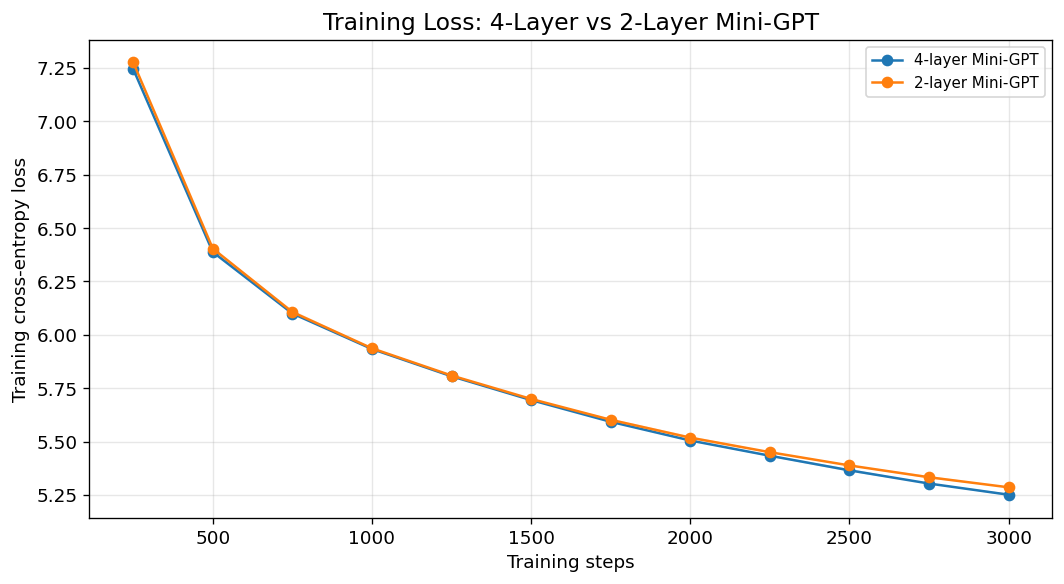

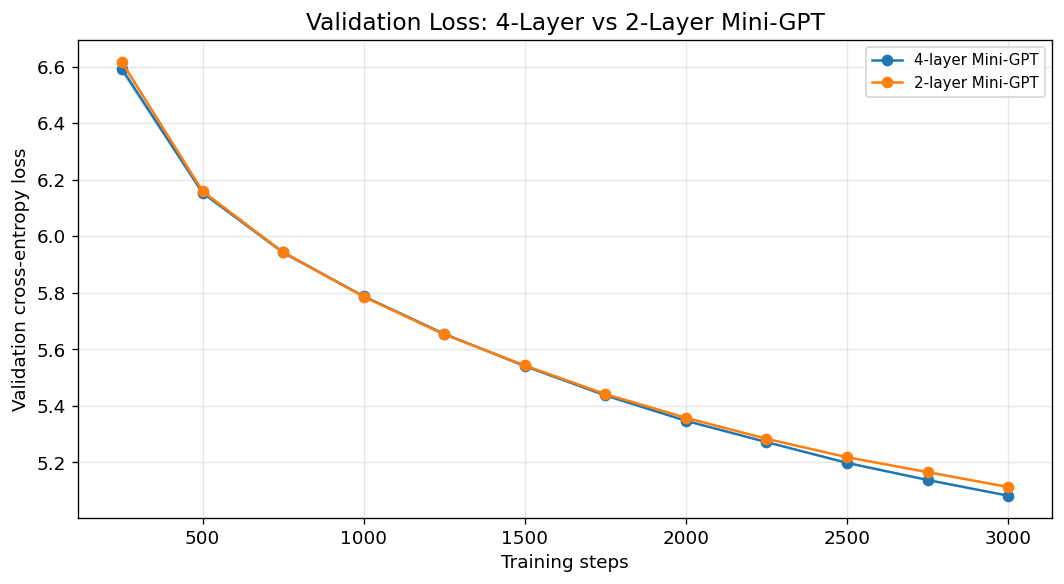

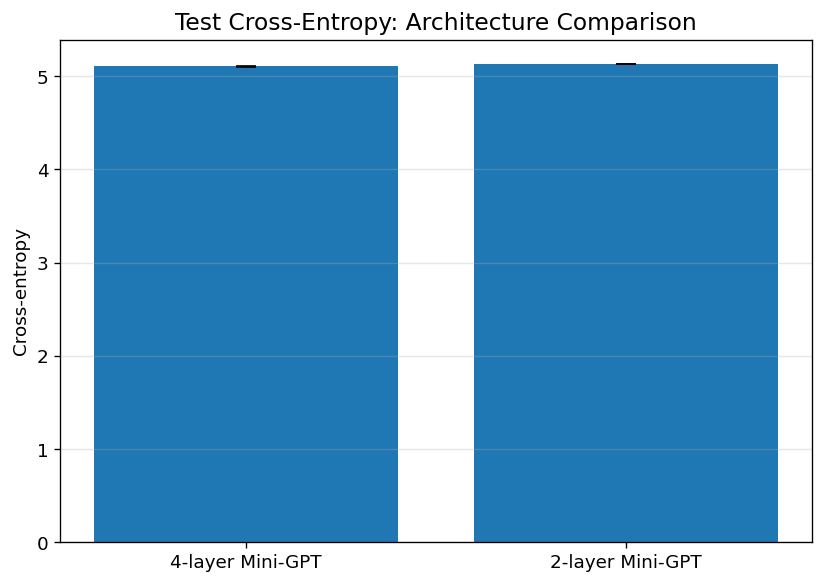

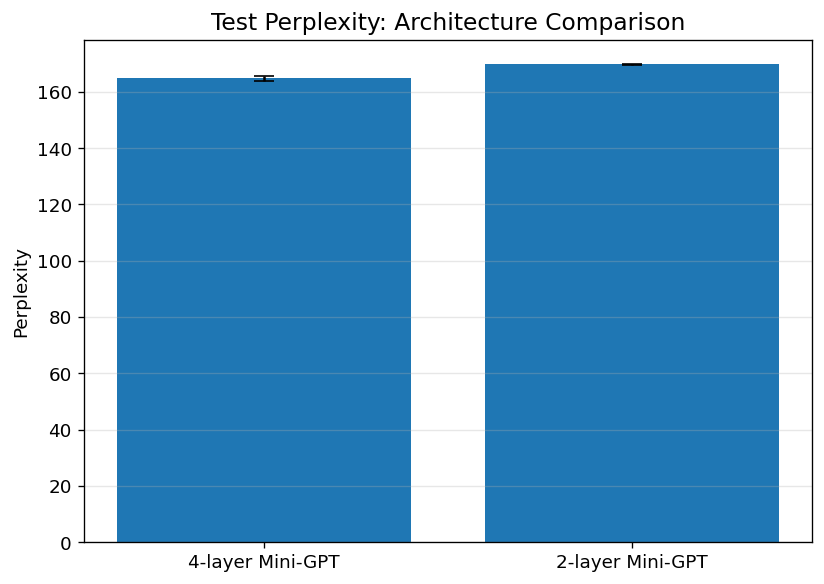

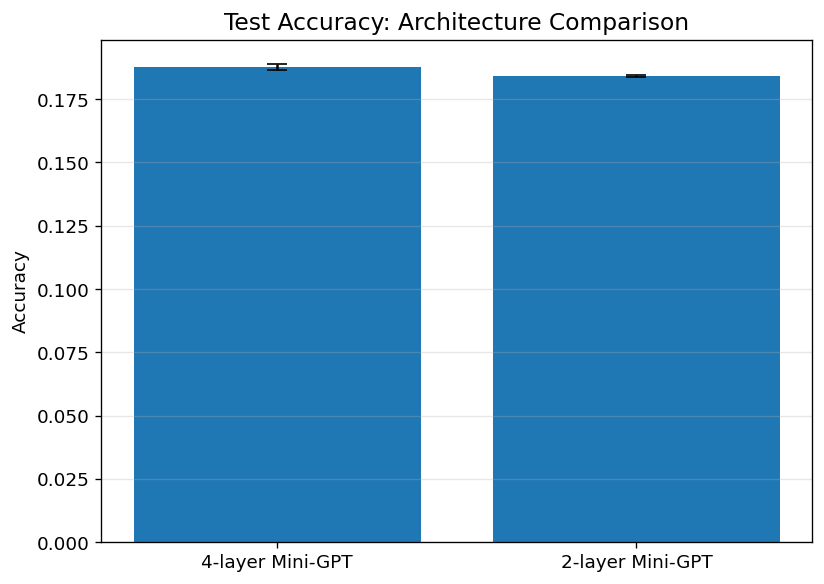

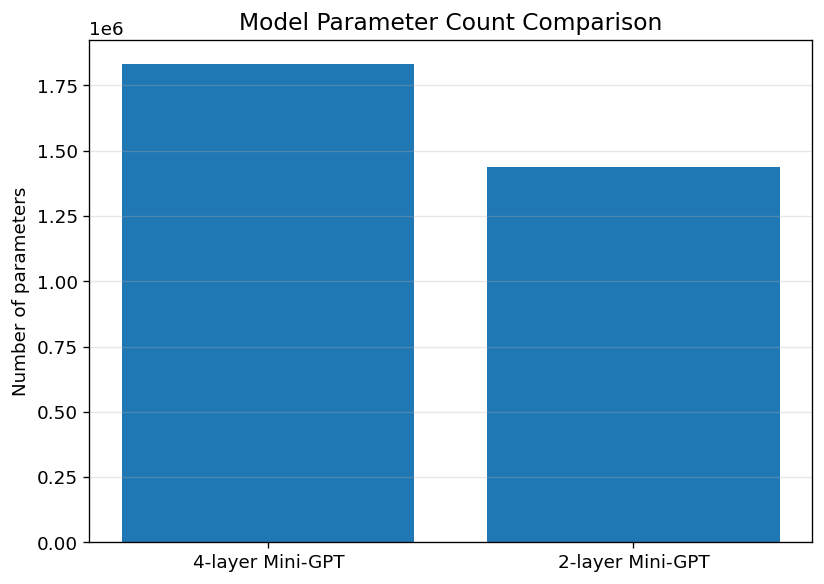

All comparison figures saved to: /content/drive/MyDrive/Mini-GPT-Project/experiments/architecture_ablation/plots
CSV saved to: /content/drive/MyDrive/Mini-GPT-Project/experiments/architecture_ablation/architecture_ablation_results.csv

Interpretation:
{
    "experiment": "Controlled Mini-GPT depth ablation",
    "four_layer_mean_test_cross_entropy": 5.104793702623281,
    "two_layer_mean_test_cross_entropy": 5.134275121817496,
    "test_cross_entropy_difference": 0.029481419194214986,
    "parameter_reduction_percent": 21.625017450788775,
    "interpretation": "The two-layer model has fewer parameters but higher test cross-entropy. The four-layer model achieves better test prediction quality across all three seeds."
}


In [42]:
import json
import csv
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================================
# 1. Paths
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")

RESULTS_DIR = (
    PROJECT_DIR / "experiments/architecture_ablation"
)

RUNS_DIR = RESULTS_DIR / "controlled_runs"
PLOTS_DIR = RESULTS_DIR / "plots"

PLOTS_DIR.mkdir(parents=True, exist_ok=True)

with open(
    RESULTS_DIR / "architecture_test_comparison.json", "r"
) as f:
    report = json.load(f)

SEEDS = [42, 123, 2026]

ARCHITECTURES = {
    "baseline_4_layers": "4-layer Mini-GPT",
    "ablation_2_layers": "2-layer Mini-GPT"
}


# ============================================================
# 2. Load training histories
# ============================================================

histories = {}

for architecture in ARCHITECTURES:

    histories[architecture] = []

    for seed in SEEDS:

        history_path = (
            RUNS_DIR
            / f"{architecture}_seed_{seed}"
            / "training_history.json"
        )

        with open(history_path, "r") as f:
            history = json.load(f)

        histories[architecture].append(history)

# Verify that all runs have matching evaluation steps.
reference_steps = histories["baseline_4_layers"][0]["step"]

for architecture in ARCHITECTURES:
    for history in histories[architecture]:
        if history["step"] != reference_steps:
            raise ValueError(
                "Training histories have inconsistent step values."
            )


# ============================================================
# 3. Plot mean training loss ± standard deviation
# ============================================================

plt.figure(figsize=(9, 5))

for architecture, label in ARCHITECTURES.items():

    losses = np.array([
        history["train_loss"]
        for history in histories[architecture]
    ])

    mean_loss = losses.mean(axis=0)
    std_loss = losses.std(axis=0, ddof=1)

    plt.plot(
        reference_steps,
        mean_loss,
        marker="o",
        label=label
    )

    plt.fill_between(
        reference_steps,
        mean_loss - std_loss,
        mean_loss + std_loss,
        alpha=0.2
    )

plt.xlabel("Training steps")
plt.ylabel("Training cross-entropy loss")
plt.title("Training Loss: 4-Layer vs 2-Layer Mini-GPT")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "training_loss_comparison.png",
    dpi=300
)

plt.show()


# ============================================================
# 4. Plot mean validation loss ± standard deviation
# ============================================================

plt.figure(figsize=(9, 5))

for architecture, label in ARCHITECTURES.items():

    losses = np.array([
        history["validation_loss"]
        for history in histories[architecture]
    ])

    mean_loss = losses.mean(axis=0)
    std_loss = losses.std(axis=0, ddof=1)

    plt.plot(
        reference_steps,
        mean_loss,
        marker="o",
        label=label
    )

    plt.fill_between(
        reference_steps,
        mean_loss - std_loss,
        mean_loss + std_loss,
        alpha=0.2
    )

plt.xlabel("Training steps")
plt.ylabel("Validation cross-entropy loss")
plt.title("Validation Loss: 4-Layer vs 2-Layer Mini-GPT")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "validation_loss_comparison.png",
    dpi=300
)

plt.show()


# ============================================================
# 5. Plot test metric comparisons
# ============================================================

aggregate = report["aggregate_results"]

metrics_to_plot = [
    ("cross_entropy", "Test Cross-Entropy", "Cross-entropy"),
    ("perplexity", "Test Perplexity", "Perplexity"),
    ("accuracy", "Test Accuracy", "Accuracy")
]

for metric, title, ylabel in metrics_to_plot:

    means = [
        aggregate[architecture][metric]["mean"]
        for architecture in ARCHITECTURES
    ]

    stds = [
        aggregate[architecture][metric]["std"]
        for architecture in ARCHITECTURES
    ]

    labels = list(ARCHITECTURES.values())
    x = np.arange(len(labels))

    plt.figure(figsize=(7, 5))

    plt.bar(
        x,
        means,
        yerr=stds,
        capsize=6
    )

    plt.xticks(x, labels)
    plt.ylabel(ylabel)
    plt.title(title + ": Architecture Comparison")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    filename = metric + "_comparison.png"

    plt.savefig(
        PLOTS_DIR / filename,
        dpi=300
    )

    plt.show()


# ============================================================
# 6. Parameter count comparison
# ============================================================

parameter_counts = [
    aggregate[architecture]["parameter_count"]
    for architecture in ARCHITECTURES
]

labels = list(ARCHITECTURES.values())
x = np.arange(len(labels))

plt.figure(figsize=(7, 5))

plt.bar(x, parameter_counts)

plt.xticks(x, labels)
plt.ylabel("Number of parameters")
plt.title("Model Parameter Count Comparison")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "parameter_count_comparison.png",
    dpi=300
)

plt.show()


# ============================================================
# 7. Export individual experiment results to CSV
# ============================================================

CSV_PATH = RESULTS_DIR / "architecture_ablation_results.csv"

fieldnames = [
    "architecture",
    "seed",
    "test_cross_entropy",
    "test_perplexity",
    "test_accuracy",
    "validation_loss",
    "parameter_count",
    "checkpoint_size_MB"
]

with open(CSV_PATH, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fieldnames
    )

    writer.writeheader()

    for run_name, metrics in report["results_by_run"].items():

        architecture, seed_text = run_name.rsplit("_seed_", 1)

        writer.writerow({
            "architecture": architecture,
            "seed": int(seed_text),
            "test_cross_entropy": metrics["cross_entropy"],
            "test_perplexity": metrics["perplexity"],
            "test_accuracy": metrics["accuracy"],
            "validation_loss": metrics["best_validation_loss"],
            "parameter_count": metrics["parameter_count"],
            "checkpoint_size_MB": metrics["checkpoint_size_MB"]
        })


# ============================================================
# 8. Save a short interpretation report
# ============================================================

four_layer_ce = aggregate["baseline_4_layers"]["cross_entropy"]["mean"]
two_layer_ce = aggregate["ablation_2_layers"]["cross_entropy"]["mean"]

four_layer_params = aggregate["baseline_4_layers"]["parameter_count"]
two_layer_params = aggregate["ablation_2_layers"]["parameter_count"]

parameter_reduction = (
    (four_layer_params - two_layer_params)
    / four_layer_params * 100
)

ce_difference = two_layer_ce - four_layer_ce

interpretation = {
    "experiment": "Controlled Mini-GPT depth ablation",
    "four_layer_mean_test_cross_entropy": four_layer_ce,
    "two_layer_mean_test_cross_entropy": two_layer_ce,
    "test_cross_entropy_difference": ce_difference,
    "parameter_reduction_percent": parameter_reduction,
    "interpretation": (
        "The two-layer model has fewer parameters but higher "
        "test cross-entropy. The four-layer model achieves better "
        "test prediction quality across all three seeds."
    )
}

INTERPRETATION_PATH = (
    RESULTS_DIR / "architecture_ablation_interpretation.json"
)

with open(INTERPRETATION_PATH, "w") as f:
    json.dump(interpretation, f, indent=4)


# ============================================================
# 9. Final output
# ============================================================

print("All comparison figures saved to:", PLOTS_DIR)
print("CSV saved to:", CSV_PATH)
print("\nInterpretation:")
print(json.dumps(interpretation, indent=4))

## Step 10B — Export the Mini-GPT Architecture

Export the trained Mini-GPT architecture and its dependent custom classes from the current notebook into model.py.

The exported file must preserve:
- Token and positional embeddings.
- Transformer blocks.
- Causal self-attention.
- Feed-forward networks.
- Layer normalization.
- The tied token embedding and output projection weights.

Test the exported implementation by loading a saved four-layer checkpoint and comparing its outputs with the original notebook implementation.

This ensures that the deployment model uses the same architecture as the trained model.

In [44]:
import ast
import json
import torch
import importlib.util
from pathlib import Path

# ============================================================
# 1. Paths
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")
APP_DIR = PROJECT_DIR / "chatty_app"
APP_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = APP_DIR / "model.py"

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "experiments/architecture_ablation/controlled_runs/"
    / "baseline_4_layers_seed_123/best_model.pt"
)

# ============================================================
# 2. Access executed notebook history
# ============================================================

ip = get_ipython()

if ip is None or "In" not in ip.user_ns:
    raise RuntimeError("Colab notebook history is unavailable.")

history = ip.user_ns["In"]

definitions = {}
assignments = {}
parsed_cells = {}

def extract_targets(node):

    targets = []

    if isinstance(node, ast.Name):
        targets.append(node.id)

    elif isinstance(node, (ast.Tuple, ast.List)):
        for item in node.elts:
            targets.extend(extract_targets(item))

    return targets


# Index all class/function definitions and assignments.
for cell_index, source in enumerate(history):

    if not isinstance(source, str) or not source.strip():
        continue

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    parsed_cells[cell_index] = (source, tree)

    for node in tree.body:

        if isinstance(
            node,
            (ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            definitions.setdefault(node.name, []).append(
                (cell_index, node)
            )

        elif isinstance(node, (ast.Assign, ast.AnnAssign)):

            targets = (
                node.targets
                if isinstance(node, ast.Assign)
                else [node.target]
            )

            for target in targets:
                for name in extract_targets(target):
                    assignments.setdefault(name, []).append(
                        (cell_index, node)
                    )


if "MiniGPT" not in definitions:
    raise RuntimeError(
        "MiniGPT was not found in notebook history. "
        "Re-run the original cell defining MiniGPT."
    )

# Use the latest MiniGPT definition.
model_definition = max(
    definitions["MiniGPT"],
    key=lambda item: item[0]
)

model_cell_index, model_node = model_definition

print("MiniGPT definition found in notebook cell:", model_cell_index)


# ============================================================
# 3. Recover required dependencies
# ============================================================

selected_nodes = []
selected_keys = set()
selected_cell_indices = set()

def get_node_source(cell_index, node):

    source = parsed_cells[cell_index][0]
    lines = source.splitlines()

    start = node.lineno

    if hasattr(node, "decorator_list") and node.decorator_list:
        start = min(
            start,
            min(d.lineno for d in node.decorator_list)
        )

    end = node.end_lineno

    return "\n".join(lines[start - 1:end])


def resolve_name(name, before_index):

    candidates = definitions.get(name, [])

    if candidates:

        eligible = [
            item for item in candidates
            if item[0] <= before_index
        ]

        if not eligible:
            eligible = candidates

        cell_index, node = max(
            eligible,
            key=lambda item: item[0]
        )

    else:

        candidates = assignments.get(name, [])

        if not candidates:
            return

        eligible = [
            item for item in candidates
            if item[0] <= before_index
        ]

        if not eligible:
            return

        cell_index, node = max(
            eligible,
            key=lambda item: item[0]
        )

    key = (cell_index, node.lineno, node.end_lineno)

    if key in selected_keys:
        return

    selected_keys.add(key)
    selected_cell_indices.add(cell_index)

    # Resolve dependencies before adding this definition.
    for child in ast.walk(node):

        if isinstance(child, ast.Name):
            if isinstance(child.ctx, ast.Load):
                resolve_name(child.id, cell_index)

    selected_nodes.append((cell_index, node))


resolve_name("MiniGPT", model_cell_index)


# ============================================================
# 4. Recover imports used by the selected definitions
# ============================================================

used_names = set()

for cell_index, node in selected_nodes:
    for child in ast.walk(node):
        if isinstance(child, ast.Name):
            used_names.add(child.id)

captured_imports = []

for cell_index in sorted(selected_cell_indices):

    source, tree = parsed_cells[cell_index]

    for node in tree.body:

        if not isinstance(node, (ast.Import, ast.ImportFrom)):
            continue

        if isinstance(node, ast.Import):

            imported_names = [
                alias.asname or alias.name.split(".")[0]
                for alias in node.names
            ]

        else:

            imported_names = [
                alias.asname or alias.name
                for alias in node.names
            ]

        if any(name in used_names for name in imported_names):

            import_source = get_node_source(cell_index, node)

            if import_source not in captured_imports:
                captured_imports.append(import_source)


# ============================================================
# 5. Generate model.py
# ============================================================

base_imports = [
    "import math",
    "import torch",
    "import torch.nn as nn",
    "import torch.nn.functional as F"
]

definitions_source = []

for cell_index, node in selected_nodes:

    definitions_source.append(
        get_node_source(cell_index, node)
    )

model_source = (
    "\n".join(base_imports)
    + "\n\n"
    + "\n\n".join(captured_imports)
    + "\n\n"
    + "\n\n".join(definitions_source)
    + "\n"
)

MODEL_PATH.write_text(
    model_source,
    encoding="utf-8"
)

print("\nmodel.py exported:", MODEL_PATH)
print("Definitions exported:", len(selected_nodes))
print("Imports recovered:", len(captured_imports))


# ============================================================
# 6. Import the exported model
# ============================================================

spec = importlib.util.spec_from_file_location(
    "chatty_model",
    MODEL_PATH
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

ExportedMiniGPT = module.MiniGPT


# ============================================================
# 7. Load the selected checkpoint
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model_config = checkpoint["model_config"]
state_dict = checkpoint["model_state_dict"]

original_model = MiniGPT(model_config).cpu()
original_model.load_state_dict(state_dict, strict=True)
original_model.eval()

exported_model = ExportedMiniGPT(model_config).cpu()
exported_model.load_state_dict(state_dict, strict=True)
exported_model.eval()


# ============================================================
# 8. Compare outputs
# ============================================================

torch.manual_seed(42)

test_input = torch.randint(
    0,
    model_config["vocab_size"],
    (2, 32)
)

with torch.inference_mode():

    original_logits = original_model(test_input)
    exported_logits = exported_model(test_input)

max_difference = (
    original_logits - exported_logits
).abs().max().item()

outputs_match = torch.allclose(
    original_logits,
    exported_logits,
    atol=1e-6,
    rtol=1e-5
)

parameter_count = sum(
    p.numel() for p in exported_model.parameters()
)

report = {
    "model_file": str(MODEL_PATH),
    "checkpoint": str(CHECKPOINT_PATH),
    "parameter_count": parameter_count,
    "output_shape": list(exported_logits.shape),
    "maximum_absolute_difference": max_difference,
    "outputs_match": outputs_match
}

REPORT_PATH = APP_DIR / "model_export_test.json"

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=4)

print("\nEXPORT VERIFICATION")
print(json.dumps(report, indent=4))

if not outputs_match:
    raise RuntimeError(
        "Export verification failed. Do not use this model.py yet."
    )

print("\nMini-GPT architecture exported and verified successfully.")

MiniGPT definition found in notebook cell: 8

model.py exported: /content/drive/MyDrive/Mini-GPT-Project/chatty_app/model.py
Definitions exported: 12
Imports recovered: 6

EXPORT VERIFICATION
{
    "model_file": "/content/drive/MyDrive/Mini-GPT-Project/chatty_app/model.py",
    "checkpoint": "/content/drive/MyDrive/Mini-GPT-Project/experiments/architecture_ablation/controlled_runs/baseline_4_layers_seed_123/best_model.pt",
    "parameter_count": 1833728,
    "output_shape": [
        2,
        32,
        8000
    ],
    "maximum_absolute_difference": 0.0,
    "outputs_match": true
}

Mini-GPT architecture exported and verified successfully.


## Step 10C — Locate and Inspect the Trained BPE Tokenizer

Inspect the existing Mini-GPT project to locate the trained BPE tokenizer implementation and its saved assets.

Identify:
- The tokenizer class or implementation.
- The vocabulary and merge files.
- The encoding and decoding methods.
- The special token IDs: PAD, UNK, BOS, and EOS.
- The tokenizer vocabulary size.

This step prepares the tokenizer for deployment without modifying the original training artifacts.

In [45]:
import ast
from pathlib import Path
import inspect

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")

# ============================================================
# 1. Search saved tokenizer-related files
# ============================================================

skip_directories = {
    ".git",
    "node_modules",
    "__pycache__"
}

keywords = [
    "tokenizer",
    "vocab",
    "merge",
    "bpe"
]

print("=" * 65)
print("TOKENIZER FILES")
print("=" * 65)

tokenizer_files = []

for path in PROJECT_DIR.rglob("*"):

    if not path.is_file():
        continue

    if any(part in skip_directories for part in path.parts):
        continue

    relative_path = str(path.relative_to(PROJECT_DIR)).lower()

    if any(keyword in relative_path for keyword in keywords):

        tokenizer_files.append(path)

        print(
            path.relative_to(PROJECT_DIR),
            f"({path.stat().st_size / 1024:.1f} KB)"
        )

if not tokenizer_files:
    print("No tokenizer-related files found.")


# ============================================================
# 2. Inspect tokenizer definitions in notebook history
# ============================================================

print("\n" + "=" * 65)
print("TOKENIZER DEFINITIONS IN NOTEBOOK")
print("=" * 65)

history = get_ipython().user_ns["In"]

definition_names = []

for cell_index, source in enumerate(history):

    if not isinstance(source, str):
        continue

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(
            node,
            (ast.ClassDef, ast.FunctionDef)
        ):

            name = node.name.lower()

            if any(
                keyword in name
                for keyword in [
                    "token",
                    "bpe",
                    "encode",
                    "decode"
                ]
            ):

                definition_names.append(
                    (cell_index, node.name)
                )

                print(
                    f"Cell {cell_index}: {node.name}"
                )


# ============================================================
# 3. Inspect tokenizer-related live variables
# ============================================================

print("\n" + "=" * 65)
print("LIVE NOTEBOOK VARIABLES")
print("=" * 65)

for name, value in list(globals().items()):

    if any(
        keyword in name.lower()
        for keyword in [
            "tokenizer",
            "vocab",
            "bpe"
        ]
    ):

        if name.startswith("_"):
            continue

        print(
            name,
            "->",
            type(value).__name__
        )

        if hasattr(value, "vocab_size"):
            try:
                print("  vocab_size:", value.vocab_size)
            except Exception:
                pass

        if hasattr(value, "get_vocab_size"):
            try:
                print("  get_vocab_size:", value.get_vocab_size())
            except Exception:
                pass


# ============================================================
# 4. Display known special token IDs
# ============================================================

print("\n" + "=" * 65)
print("KNOWN TOKENIZER CONFIGURATION")
print("=" * 65)

print({
    "vocab_size": 8000,
    "PAD": 0,
    "UNK": 1,
    "BOS": 2,
    "EOS": 3
})

# ============================================================
# 5. Save inspection report
# ============================================================

APP_DIR = PROJECT_DIR / "chatty_app"

report = {
    "tokenizer_files": [
        str(path.relative_to(PROJECT_DIR))
        for path in tokenizer_files
    ],
    "notebook_definitions": [
        {
            "cell": cell,
            "name": name
        }
        for cell, name in definition_names
    ],
    "special_tokens": {
        "PAD": 0,
        "UNK": 1,
        "BOS": 2,
        "EOS": 3
    },
    "vocab_size": 8000
}

import json

REPORT_PATH = APP_DIR / "tokenizer_inspection.json"

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=4)

print("\nInspection report saved:", REPORT_PATH)

TOKENIZER FILES
results/graphs/tokenizer_statistics.png (246.1 KB)
data/tokenizer/bpe_tokenizer.json (524.0 KB)
data/tokenizer/tokenizer_metadata.json (0.5 KB)

TOKENIZER DEFINITIONS IN NOTEBOOK
Cell 6: encode_text_file

LIVE NOTEBOOK VARIABLES
Tokenizer -> type
pre_tokenizers -> module
TOKENIZER_DIR -> PosixPath
TOKENIZER_PATH -> PosixPath
TOKENIZER_METADATA_PATH -> PosixPath
VOCAB_SIZE -> int
tokenizer -> Tokenizer
  get_vocab_size: 8000
vocab -> dict
actual_vocab_size -> int
reloaded_tokenizer -> Tokenizer
  get_vocab_size: 8000
vocab_size -> int
tokenizer_files -> list

KNOWN TOKENIZER CONFIGURATION
{'vocab_size': 8000, 'PAD': 0, 'UNK': 1, 'BOS': 2, 'EOS': 3}

Inspection report saved: /content/drive/MyDrive/Mini-GPT-Project/chatty_app/tokenizer_inspection.json


In [46]:
import json
import shutil
import sys
import subprocess
import importlib.util

from pathlib import Path

# ============================================================
# 1. Define paths
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/Mini-GPT-Project")

SOURCE_DIR = PROJECT_DIR / "data/tokenizer"

APP_DIR = PROJECT_DIR / "chatty_app"
TOKENIZER_ASSETS = APP_DIR / "tokenizer_assets"

TOKENIZER_ASSETS.mkdir(parents=True, exist_ok=True)

TOKENIZER_JSON = SOURCE_DIR / "bpe_tokenizer.json"
METADATA_JSON = SOURCE_DIR / "tokenizer_metadata.json"

if not TOKENIZER_JSON.exists():
    raise FileNotFoundError(TOKENIZER_JSON)

if not METADATA_JSON.exists():
    raise FileNotFoundError(METADATA_JSON)

# ============================================================
# 2. Ensure tokenizers package is installed
# ============================================================

if importlib.util.find_spec("tokenizers") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "tokenizers"
    ])

from tokenizers import Tokenizer

# ============================================================
# 3. Copy original tokenizer assets
# ============================================================

shutil.copy2(
    TOKENIZER_JSON,
    TOKENIZER_ASSETS / "bpe_tokenizer.json"
)

shutil.copy2(
    METADATA_JSON,
    TOKENIZER_ASSETS / "tokenizer_metadata.json"
)

# ============================================================
# 4. Load tokenizer and metadata
# ============================================================

tokenizer = Tokenizer.from_file(
    str(TOKENIZER_ASSETS / "bpe_tokenizer.json")
)

with open(
    TOKENIZER_ASSETS / "tokenizer_metadata.json",
    "r",
    encoding="utf-8"
) as f:
    metadata = json.load(f)

# ============================================================
# 5. Verify vocabulary and special token IDs
# ============================================================

vocab_size = tokenizer.get_vocab_size()

special_tokens = {
    "PAD": 0,
    "UNK": 1,
    "BOS": 2,
    "EOS": 3
}

print("Vocabulary size:", vocab_size)
print("\nMetadata:")
print(json.dumps(metadata, indent=4, ensure_ascii=False))

print("\nVocabulary token IDs:")

for token_name, expected_id in special_tokens.items():

    metadata_candidates = [
        token_name,
        token_name.lower(),
        f"{token_name}_id",
        f"{token_name.lower()}_id"
    ]

    actual_id = None

    for candidate in metadata_candidates:
        if candidate in metadata:
            actual_id = metadata[candidate]
            break

    print(
        token_name,
        "expected:",
        expected_id,
        "metadata:",
        actual_id
    )

# ============================================================
# 6. Test encoding and decoding
# ============================================================

test_text = "Chatty is a small language model."

encoded = tokenizer.encode(test_text)

decoded = tokenizer.decode(
    encoded.ids,
    skip_special_tokens=True
)

print("\nEncoding test:")
print("Original text:", test_text)
print("Token IDs:", encoded.ids)
print("Decoded text:", decoded)

print("\nSpecial token lookup:")

for token_id in range(4):
    print(
        token_id,
        "->",
        tokenizer.id_to_token(token_id)
    )

# ============================================================
# 7. Create tokenizer.py
# ============================================================

tokenizer_source = r'''
import json
from pathlib import Path

from tokenizers import Tokenizer


APP_DIR = Path(__file__).resolve().parent

TOKENIZER_PATH = (
    APP_DIR / "tokenizer_assets" / "bpe_tokenizer.json"
)

METADATA_PATH = (
    APP_DIR / "tokenizer_assets" / "tokenizer_metadata.json"
)


PAD_ID = 0
UNK_ID = 1
BOS_ID = 2
EOS_ID = 3

VOCAB_SIZE = 8000


def load_metadata():
    if not METADATA_PATH.exists():
        raise FileNotFoundError(
            f"Tokenizer metadata not found: {METADATA_PATH}"
        )

    with open(METADATA_PATH, "r", encoding="utf-8") as file:
        return json.load(file)


def load_tokenizer():
    if not TOKENIZER_PATH.exists():
        raise FileNotFoundError(
            f"Tokenizer file not found: {TOKENIZER_PATH}"
        )

    tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))

    actual_size = tokenizer.get_vocab_size()

    if actual_size != VOCAB_SIZE:
        raise ValueError(
            f"Expected vocabulary size {VOCAB_SIZE}, "
            f"but found {actual_size}."
        )

    return tokenizer


def encode_text(text, add_special_tokens=True):
    if not isinstance(text, str):
        raise TypeError("Input must be a string.")

    tokenizer = load_tokenizer()

    return tokenizer.encode(
        text,
        add_special_tokens=add_special_tokens
    ).ids


def decode_tokens(token_ids, skip_special_tokens=True):
    if not isinstance(token_ids, (list, tuple)):
        raise TypeError("token_ids must be a list or tuple.")

    tokenizer = load_tokenizer()

    return tokenizer.decode(
        list(token_ids),
        skip_special_tokens=skip_special_tokens
    )


# Load once when the module is imported.
tokenizer = load_tokenizer()
metadata = load_metadata()
'''

TOKENIZER_MODULE_PATH = APP_DIR / "tokenizer.py"

TOKENIZER_MODULE_PATH.write_text(
    tokenizer_source,
    encoding="utf-8"
)

print("\ntokenizer.py created:", TOKENIZER_MODULE_PATH)

# ============================================================
# 8. Verify the exported tokenizer module
# ============================================================

import importlib.util

spec = importlib.util.spec_from_file_location(
    "chatty_tokenizer",
    TOKENIZER_MODULE_PATH
)

tokenizer_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = tokenizer_module
spec.loader.exec_module(tokenizer_module)

test_ids = tokenizer_module.encode_text(
    test_text,
    add_special_tokens=False
)

test_decoded = tokenizer_module.decode_tokens(test_ids)

verification = {
    "vocabulary_size": tokenizer_module.tokenizer.get_vocab_size(),
    "PAD_ID": tokenizer_module.PAD_ID,
    "UNK_ID": tokenizer_module.UNK_ID,
    "BOS_ID": tokenizer_module.BOS_ID,
    "EOS_ID": tokenizer_module.EOS_ID,
    "test_encoding": test_ids,
    "test_decoding": test_decoded,
    "tokenizer_assets_copied": True,
    "tokenizer_module_created": TOKENIZER_MODULE_PATH.exists()
}

REPORT_PATH = APP_DIR / "tokenizer_export_test.json"

with open(REPORT_PATH, "w") as f:
    json.dump(verification, f, indent=4, ensure_ascii=False)

print("\nTOKENIZER VERIFICATION")
print(json.dumps(verification, indent=4, ensure_ascii=False))
print("\nReport saved:", REPORT_PATH)

Vocabulary size: 8000

Metadata:
{
    "sample_entries": 5000,
    "vocabulary_size": 8000,
    "target_vocabulary_size": 8000,
    "tokenizer_training_time_seconds": 186.42,
    "mean_characters_per_entry": 445.038,
    "mean_words_per_entry": 84.2022,
    "mean_tokens_per_entry": 112.0942,
    "tokens_per_word": 1.3312502523687029,
    "characters_per_token": 3.970214337583925,
    "special_token_ids": {
        "[PAD]": 0,
        "[UNK]": 1,
        "[BOS]": 2,
        "[EOS]": 3
    }
}

Vocabulary token IDs:
PAD expected: 0 metadata: None
UNK expected: 1 metadata: None
BOS expected: 2 metadata: None
EOS expected: 3 metadata: None

Encoding test:
Original text: Chatty is a small language model.
Token IDs: [5625, 713, 92, 377, 262, 1259, 3259, 3459, 17]
Decoded text: Chatty is a small language model.

Special token lookup:
0 -> [PAD]
1 -> [UNK]
2 -> [BOS]
3 -> [EOS]

tokenizer.py created: /content/drive/MyDrive/Mini-GPT-Project/chatty_app/tokenizer.py

TOKENIZER VERIFICATION
{
    